# Causal ML stock-selection strategy with cash-aware overlays

This notebook tests a Ridge ML Swiss equity stock-selection strategy with causal JKP features, long-only ScoreVariance optimization, and three predeclared exposure overlays. Strategy selection is based only on validation-period performance; the test period is reported after selection and is not used to choose the final strategy.

## Strategy Overview

This notebook builds a causal version of the machine-learning stock-selection strategy for the Swiss equity universe. The core idea is simple: at each quarterly rebalance date, we use only information that would have been available at that time, train a Ridge regression model on past cross-sections, predict stock-level forward returns, and convert those predictions into portfolio inputs for a long-only optimizer.

The strategy uses JKP-style firm characteristics as features. The feature data are handled with an as-of/lag rule so that the model does not accidentally see future accounting or return information. The prediction target is the next rebalance-period stock return, tested in two forms: a cross-sectional z-score label and a cross-sectional rank label.

The grid search tests three design blocks:

| Block | Variants | Purpose |
| --- | --- | --- |
| Feature set | CORE, EXPANDED | Compare a smaller robust characteristic set against a richer signal set. |
| ML label | zscore_label, rank_label | Compare direct standardized return prediction with ordinal cross-sectional ranking. |
| Optimizer preset | base, aggressive, conservative | Compare different ScoreVariance risk/turnover/position-limit settings. |
| Overlay | no_overlay, trend_binary_250, trend_soft_250 | Compare full equity exposure with two SPI trend-based cash overlays. |

This gives 2 x 2 x 3 = 12 base ML/optimizer backtests, and each base strategy is evaluated under 3 overlay rules, for 36 total strategy variants. The overlay is applied after the stock-selection portfolio is formed: when the SPI trend signal is weak, part or all of the portfolio is moved to the Swiss risk-free proxy/cash return. Overlay changes include transaction costs.

Selection is intentionally done using the validation period only, ending on 2016-12-31. The test period from 2017 onward is used only as an out-of-sample diagnostic. This means the notebook avoids choosing the final strategy based on test performance. The final tables report net and gross performance, volatility, Sharpe, maximum drawdown, beta, tracking error, information ratio, exposure, and overlay costs versus the SPI benchmark.

Note: the notebook contains saved outputs from a long run. The parsed saved output currently covers 30 of the planned 36 strategy variants, so the final visible summary should be treated as a partial-grid diagnostic unless the remaining variants are rerun.


## Summary of Saved Run

The saved grid appears partial: 30/36 evaluated strategies were parsed before the run stopped or the cell ended.

Parsed rows: 90 sample rows across 30 strategy variants. Expected full grid: 36 variants, 108 validation/test/full rows.

### Validation leaderboard used for selection

| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- |
| EXPANDED / zscore_label / base / trend_binary_250 | 12.63% | 10.95% | 1.115 | -20.01% | 0.256 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | 11.61% | 10.25% | 1.096 | -18.64% | 0.254 | 65.13% |
| CORE / rank_label / conservative / trend_binary_250 | 10.88% | 9.63% | 1.092 | -16.43% | 0.240 | 65.13% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | 13.29% | 11.82% | 1.091 | -20.55% | 0.258 | 65.13% |
| CORE / zscore_label / conservative / trend_binary_250 | 10.72% | 9.84% | 1.056 | -18.33% | 0.242 | 65.13% |
| CORE / rank_label / base / trend_binary_250 | 10.99% | 10.32% | 1.036 | -18.62% | 0.242 | 65.13% |
| EXPANDED / rank_label / conservative / trend_binary_250 | 10.06% | 9.58% | 1.020 | -17.85% | 0.244 | 65.13% |
| CORE / zscore_label / base / trend_binary_250 | 10.70% | 10.35% | 1.007 | -19.83% | 0.242 | 65.13% |
| CORE / zscore_label / aggressive / trend_binary_250 | 11.30% | 10.97% | 1.006 | -21.65% | 0.242 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_soft_250 | 11.25% | 11.16% | 0.986 | -28.75% | 0.410 | 78.08% |

### Validation winners with their test and full-period performance

| Strategy | Sample | CAGR | Vol | Sharpe | MaxDD | IR | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- | --- |
| EXPANDED / zscore_label / base / trend_binary_250 | validation | 12.63% | 10.95% | 1.115 | -20.01% | 0.373 | 65.13% |
| EXPANDED / zscore_label / base / trend_binary_250 | test | 5.40% | 11.26% | 0.564 | -22.02% | -0.142 | 71.07% |
| EXPANDED / zscore_label / base / trend_binary_250 | full | 10.19% | 11.06% | 0.930 | -22.02% | 0.231 | 67.09% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | validation | 11.61% | 10.25% | 1.096 | -18.64% | 0.322 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | test | 4.23% | 10.38% | 0.495 | -20.31% | -0.250 | 71.07% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | full | 9.12% | 10.29% | 0.896 | -20.31% | 0.167 | 67.09% |
| CORE / rank_label / conservative / trend_binary_250 | validation | 10.88% | 9.63% | 1.092 | -16.43% | 0.279 | 65.13% |
| CORE / rank_label / conservative / trend_binary_250 | test | 4.58% | 12.15% | 0.467 | -29.20% | -0.191 | 71.07% |
| CORE / rank_label / conservative / trend_binary_250 | full | 8.76% | 10.53% | 0.847 | -29.20% | 0.145 | 67.09% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | validation | 13.29% | 11.82% | 1.091 | -20.55% | 0.401 | 65.13% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | test | 5.75% | 11.62% | 0.579 | -21.61% | -0.109 | 71.07% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | full | 10.75% | 11.76% | 0.924 | -21.61% | 0.261 | 67.09% |
| CORE / zscore_label / conservative / trend_binary_250 | validation | 10.72% | 9.84% | 1.056 | -18.33% | 0.270 | 65.13% |
| CORE / zscore_label / conservative / trend_binary_250 | test | 3.30% | 11.53% | 0.380 | -27.26% | -0.299 | 71.07% |
| CORE / zscore_label / conservative / trend_binary_250 | full | 8.22% | 10.43% | 0.806 | -27.26% | 0.111 | 67.09% |
| CORE / rank_label / base / trend_binary_250 | validation | 10.99% | 10.32% | 1.036 | -18.62% | 0.283 | 65.13% |
| CORE / rank_label / base / trend_binary_250 | test | 5.45% | 12.77% | 0.516 | -29.84% | -0.116 | 71.07% |
| CORE / rank_label / base / trend_binary_250 | full | 9.13% | 11.19% | 0.835 | -29.84% | 0.168 | 67.09% |
| EXPANDED / rank_label / conservative / trend_binary_250 | validation | 10.06% | 9.58% | 1.020 | -17.85% | 0.234 | 65.13% |
| EXPANDED / rank_label / conservative / trend_binary_250 | test | 3.47% | 9.81% | 0.444 | -23.13% | -0.330 | 71.07% |
| EXPANDED / rank_label / conservative / trend_binary_250 | full | 7.84% | 9.65% | 0.827 | -23.13% | 0.085 | 67.09% |
| CORE / zscore_label / base / trend_binary_250 | validation | 10.70% | 10.35% | 1.007 | -19.83% | 0.266 | 65.13% |
| CORE / zscore_label / base / trend_binary_250 | test | 4.69% | 12.09% | 0.478 | -25.32% | -0.181 | 71.07% |
| CORE / zscore_label / base / trend_binary_250 | full | 8.68% | 10.96% | 0.812 | -25.32% | 0.140 | 67.09% |

### Best test-period rows, diagnostic only

| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- |
| CORE / rank_label / aggressive / no_overlay | 9.15% | 18.83% | 0.584 | -38.07% | 1.051 | 100.00% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | 5.75% | 11.62% | 0.579 | -21.61% | 0.414 | 71.07% |
| EXPANDED / zscore_label / base / trend_binary_250 | 5.40% | 11.26% | 0.564 | -22.02% | 0.417 | 71.07% |
| EXPANDED / zscore_label / aggressive / no_overlay | 7.84% | 16.87% | 0.559 | -31.71% | 0.992 | 100.00% |
| EXPANDED / zscore_label / aggressive / trend_soft_250 | 5.96% | 12.63% | 0.558 | -26.96% | 0.631 | 83.50% |
| CORE / rank_label / aggressive / trend_binary_250 | 6.13% | 13.27% | 0.550 | -28.94% | 0.445 | 71.07% |
| CORE / rank_label / aggressive / trend_soft_250 | 6.50% | 14.32% | 0.544 | -34.86% | 0.669 | 83.50% |
| CORE / rank_label / base / no_overlay | 7.89% | 18.33% | 0.531 | -38.29% | 1.067 | 100.00% |

### Overlay check

- no_overlay: 10 validation rows, avg Sharpe 0.527
- trend_binary_250: 10 validation rows, avg Sharpe 1.050
- trend_soft_250: 10 validation rows, avg Sharpe 0.930

Interpretation: choose by validation ranking only. The test-period table is a diagnostic sanity check, not a selection rule.

## 1 - Imports, paths, and global configuration

In [10]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

THIS_DIR = Path.cwd()


def find_project_root(start: Path) -> Path:
    for p in [start] + list(start.parents):
        if (p / "framework").is_dir():
            return p
    raise FileNotFoundError("Could not find the repository root containing framework/")


PROJECT_ROOT = find_project_root(THIS_DIR)
DATA_DIR = PROJECT_ROOT / "data"
SRC_DIR = PROJECT_ROOT / "framework"
RF_CSV = DATA_DIR / "IRSTCI01CHM156N.csv"

for path in [SRC_DIR, PROJECT_ROOT / "signals", PROJECT_ROOT / "data_utils"]:
    path_str = str(path)
    if path_str not in sys.path:
        sys.path.append(path_str)

from helper_functions import load_data_spi, align_market_data_with_jkp_data
from estimation.covariance import Covariance
from optimization.optimization import ScoreVariance
from backtesting.backtest_item_builder.bib_classes import SelectionItemBuilder, OptimizationItemBuilder
from backtesting.backtest_item_builder.bibfn_selection import bibfn_selection_gaps, bibfn_selection_min_volume
from backtesting.backtest_item_builder.bibfn_optimization_data import bibfn_return_series
from backtesting.backtest_item_builder.bibfn_constraints import bibfn_budget_constraint, bibfn_box_constraints
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.backtest import Backtest
import swiss_rf as srf

warnings.simplefilter("ignore", category=FutureWarning)

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002
VALIDATION_END_DATE = pd.Timestamp("2016-12-31")
N_PER_YEAR = 252
RANDOM_STATE = 31

for required in [DATA_DIR / "market_data.parquet", DATA_DIR / "jkp_data.parquet", DATA_DIR / "spi_index.csv", RF_CSV]:
    if not required.exists():
        raise FileNotFoundError(f"Missing data file: {required}. See data/README.md.")


def title(text):
    print("\n" + "=" * 110)
    print(text)
    print("=" * 110)


def print_table(name, df, max_rows=None, index=False):
    print("\n" + "-" * 110)
    print(name)
    print("-" * 110)
    if df is None or len(df) == 0:
        print("EMPTY")
        return
    x = df.copy()
    if max_rows is not None:
        x = x.head(max_rows)
    print(x.to_string(index=index))


title("PATHS")
print("THIS_DIR:", THIS_DIR)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("SRC_DIR:", SRC_DIR)
print("RF_CSV:", RF_CSV)


PATHS
THIS_DIR: <repo>/ml_stock_selection
PROJECT_ROOT: <repo>
DATA_DIR: <repo>/data
SRC_DIR: <repo>/src
RF_CSV: <repo>/ml_stock_selection/IRSTCI01CHM156N.csv


## 2 - Load and align data

In [11]:
title("LOAD AND ALIGN DATA")

market_data = pd.read_parquet(DATA_DIR / "market_data.parquet")
jkp_data = pd.read_parquet(DATA_DIR / "jkp_data.parquet")
spi = load_data_spi(path=str(DATA_DIR) + "/")
market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

return_index_for_rf = data.bm_series.index
rf_daily_full = srf.build_daily_rf(str(RF_CSV), return_index_for_rf)

load_diagnostics = pd.DataFrame([
    {"item": "market data rows", "value": market_data.shape[0]},
    {"item": "market data columns", "value": market_data.shape[1]},
    {"item": "JKP rows", "value": jkp_data.shape[0]},
    {"item": "JKP columns", "value": jkp_data.shape[1]},
    {"item": "SPI first date", "value": data.bm_series.index.min()},
    {"item": "SPI last date", "value": data.bm_series.index.max()},
    {"item": "RF first date", "value": rf_daily_full.index.min()},
    {"item": "RF last date", "value": rf_daily_full.index.max()},
    {"item": "mean annual RF applied", "value": rf_daily_full.mean() * N_PER_YEAR},
])
print_table("Data diagnostics", load_diagnostics)


LOAD AND ALIGN DATA

--------------------------------------------------------------------------------------------------------------
Data diagnostics
--------------------------------------------------------------------------------------------------------------
                  item               value
      market data rows             1434082
   market data columns                   4
              JKP rows               83421
           JKP columns                 153
        SPI first date 1999-01-02 00:00:00
         SPI last date 2024-04-30 00:00:00
         RF first date 1999-01-02 00:00:00
          RF last date 2024-04-30 00:00:00
mean annual RF applied            0.002025


## 3 - Rebalance dates

In [12]:
title("REBALANCE DATES")

n_month = 3
jkp_data_dates = jkp_data.index.get_level_values("date").unique().sort_values()
rebdates = (
    jkp_data_dates[jkp_data_dates > market_data.index.get_level_values("date").min()][::n_month]
    .strftime("%Y-%m-%d")
    .tolist()
)
rebdates = [d for d in rebdates if d > "2002-01-01" and d < rebdates[-1]]

print("Number of rebalance dates:", len(rebdates))
print("First 10 rebalance dates:", rebdates[:10])
print("Last 10 rebalance dates:", rebdates[-10:])


REBALANCE DATES
Number of rebalance dates: 88
First 10 rebalance dates: ['2002-01-31', '2002-04-30', '2002-07-31', '2002-10-31', '2003-01-31', '2003-04-30', '2003-07-31', '2003-10-31', '2004-01-31', '2004-04-30']
Last 10 rebalance dates: ['2021-07-31', '2021-10-31', '2022-01-31', '2022-04-30', '2022-07-31', '2022-10-31', '2023-01-31', '2023-04-30', '2023-07-31', '2023-10-31']


## 4 - Causal ML signal builder

In [13]:
def cs_standardize(df, lower=0.01, upper=0.99, clip=3.0):
    X = df.apply(pd.to_numeric, errors="coerce").astype(np.float64)
    lo, hi = X.quantile(lower), X.quantile(upper)
    X = X.clip(lower=lo, upper=hi, axis=1)
    X = (X - X.mean()) / X.std(ddof=0).replace(0.0, np.nan)
    return X.clip(-clip, clip).replace([np.inf, -np.inf], np.nan).fillna(0.0)


def cs_zscore(s):
    return (s - s.mean()) / (s.std(ddof=0) + 1e-12)


def jkp_asof_causal(bs, date, fields, lag_days=90, lookback_days=460):
    cutoff = pd.to_datetime(date) - pd.Timedelta(days=lag_days)
    start = cutoff - pd.Timedelta(days=lookback_days)
    d = bs.data.jkp_data.index.get_level_values("date")
    win = bs.data.jkp_data.loc[(d <= cutoff) & (d >= start), fields]
    if win.empty:
        return pd.DataFrame(columns=fields)
    return win.groupby(level="id").last()


def fwd_return(bs, d0, d1, ids):
    r = bs.data.get_return_series(end_date=d1, width=800, weekdays_only=True, fillna_value=None)
    r = r.loc[(r.index > pd.to_datetime(d0)) & (r.index <= pd.to_datetime(d1))]
    return ((1.0 + r.reindex(columns=ids)).prod(axis=0) - 1.0).dropna()


def bibfn_ml_signal_causal(bs, rebdate, **kwargs):
    fields = kwargs.get("fields")
    model_type = kwargs.get("model_type", "ridge")
    train_window_obs = int(kwargs.get("train_window_obs", 36))
    lag_days = int(kwargs.get("lag_days", 90))
    lookback_days = int(kwargs.get("lookback_days", 460))
    rank_label = bool(kwargs.get("rank_label", False))
    ridge_alpha = float(kwargs.get("ridge_alpha", 10.0))
    field_name = kwargs.get("field_name", "scores")

    if model_type != "ridge":
        raise ValueError("bibfn_ml_signal_causal currently supports only model_type='ridge'.")

    ids = list(bs.selection.selected)

    def write_zero_scores():
        bs.optimization_data["scores"] = pd.DataFrame(
            {field_name: pd.Series(0.0, index=ids, dtype=np.float64)}
        )
        return None

    if fields is None:
        fields = []
    avail = set(bs.data.jkp_data.columns)
    fields = [f for f in fields if f in avail]
    if not fields or len(ids) == 0:
        return write_zero_scores()

    Xnow_raw = jkp_asof_causal(
        bs=bs,
        date=rebdate,
        fields=fields,
        lag_days=lag_days,
        lookback_days=lookback_days,
    ).reindex(ids)
    Xnow = cs_standardize(Xnow_raw)

    rebdates_local = bs.settings["rebdates"]
    past = [d for d in rebdates_local if d < rebdate][-(train_window_obs + 1):]
    if len(past) < 3:
        return write_zero_scores()

    X_blocks = []
    y_blocks = []
    for d0, d1 in zip(past[:-1], past[1:]):
        feats = jkp_asof_causal(
            bs=bs,
            date=d0,
            fields=fields,
            lag_days=lag_days,
            lookback_days=lookback_days,
        )
        if feats.empty:
            continue

        lab = fwd_return(bs, d0, d1, feats.index)
        common = feats.index.intersection(lab.index)
        if len(common) < 10:
            continue

        Xb = cs_standardize(feats.reindex(common))
        yb = lab.reindex(common)
        if rank_label:
            yb = yb.rank(pct=True)
        else:
            yb = cs_zscore(yb)

        X_blocks.append(Xb.to_numpy(np.float64))
        y_blocks.append(yb.to_numpy(np.float64))

    if not X_blocks:
        return write_zero_scores()

    X_train = np.ascontiguousarray(np.vstack(X_blocks))
    y_train = np.concatenate(y_blocks)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=ridge_alpha)),
    ])

    try:
        model.fit(X_train, y_train)
        raw = np.asarray(
            model.predict(np.ascontiguousarray(Xnow.to_numpy(np.float64))),
            dtype=np.float64,
        )
    except Exception:
        return write_zero_scores()

    pred = cs_zscore(pd.Series(raw, index=Xnow.index))
    bs.optimization_data["scores"] = pd.DataFrame(
        {field_name: pred.reindex(ids).fillna(0.0).astype(np.float64)}
    )
    return None

## 5 - Strategy grid definitions

In [14]:
title("STRATEGY GRID DEFINITIONS")

FEATURE_SETS = {
    "CORE": [
        "ret_6_1", "ret_12_1",
        "qmj", "qmj_growth", "qmj_safety",
        "gp_at", "op_at",
        "be_me", "debt_me",
        "at_gr1", "oaccruals_at",
    ],
    "EXPANDED": [
        "ret_6_1", "ret_12_1",
        "qmj", "qmj_growth", "qmj_safety",
        "gp_at", "op_at",
        "be_me", "debt_me",
        "at_gr1", "oaccruals_at",
        "ret_3_1", "ret_12_7",
        "fcf_me", "niq_at",
        "ivol_capm_252d", "rvol_21d",
        "dolvol_126d",
    ],
}

available_feature_sets = {}
feature_rows = []
for feature_set_name, fields in FEATURE_SETS.items():
    available = [f for f in fields if f in jkp_data.columns]
    missing = [f for f in fields if f not in jkp_data.columns]
    available_feature_sets[feature_set_name] = available
    feature_rows.append({
        "feature_set": feature_set_name,
        "n_requested": len(fields),
        "n_available": len(available),
        "available_features": ", ".join(available),
        "missing_features": ", ".join(missing) if missing else "",
    })
print_table("Feature set availability", pd.DataFrame(feature_rows), max_rows=10)

LABEL_SETTINGS = {
    "zscore_label": False,
    "rank_label": True,
}

OPTIMIZER_PRESETS = {
    "conservative": {
        "risk_aversion": 200,
        "turnover_penalty": 0.50,
        "box_upper": 0.05,
    },
    "base": {
        "risk_aversion": 100,
        "turnover_penalty": 0.25,
        "box_upper": 0.075,
    },
    "aggressive": {
        "risk_aversion": 50,
        "turnover_penalty": 0.10,
        "box_upper": 0.10,
    },
}

OVERLAYS = ["no_overlay", "trend_binary_250", "trend_soft_250"]

TRAIN_WINDOW_OBS = 36
LAG_DAYS = 90
LOOKBACK_DAYS = 460
RIDGE_ALPHA = 10.0
TREND_WIN = 250
PLOT_EVERY_STRATEGY = True

expected_base_backtests = len(FEATURE_SETS) * len(LABEL_SETTINGS) * len(OPTIMIZER_PRESETS)
expected_evaluated_strategies = expected_base_backtests * len(OVERLAYS)
print("Expected base backtests:", expected_base_backtests)
print("Expected evaluated strategies:", expected_evaluated_strategies)


STRATEGY GRID DEFINITIONS

--------------------------------------------------------------------------------------------------------------
Feature set availability
--------------------------------------------------------------------------------------------------------------
feature_set  n_requested  n_available                                                                                                                                                           available_features missing_features
       CORE           11           11                                                                           ret_6_1, ret_12_1, qmj, qmj_growth, qmj_safety, gp_at, op_at, be_me, debt_me, at_gr1, oaccruals_at                 
   EXPANDED           18           18 ret_6_1, ret_12_1, qmj, qmj_growth, qmj_safety, gp_at, op_at, be_me, debt_me, at_gr1, oaccruals_at, ret_3_1, ret_12_7, fcf_me, niq_at, ivol_capm_252d, rvol_21d, dolvol_126d                 
Expected base backtests: 12
Expected eval

## 6 - Overlay functions

In [15]:
def build_exposure_overlay(spi_returns, overlay_name):
    spi_price = (1.0 + spi_returns.fillna(0.0)).cumprod()
    ma = spi_price.rolling(TREND_WIN).mean()

    if overlay_name == "no_overlay":
        exposure = pd.Series(1.0, index=spi_returns.index)

    elif overlay_name == "trend_binary_250":
        exposure = (spi_price > ma).astype(float).shift(1).fillna(0.0)

    elif overlay_name == "trend_soft_250":
        dist = (spi_price / ma - 1.0).shift(1)
        exposure = pd.Series(0.0, index=spi_returns.index)
        exposure.loc[dist >= 0.0] = 1.0
        exposure.loc[(dist < 0.0) & (dist >= -0.05)] = 0.50
        exposure.loc[dist < -0.05] = 0.25
        exposure = exposure.fillna(0.0)

    else:
        raise ValueError(overlay_name)

    return exposure.clip(0.0, 1.0).rename("exposure")


def apply_overlay_with_cash_and_costs(raw_returns, exposure, rf_daily, variable_cost, charge_overlay_cost=True):
    idx = raw_returns.index
    expo = exposure.reindex(idx).fillna(0.0)
    rf = rf_daily.reindex(idx).fillna(0.0)
    overlaid = expo * raw_returns + (1.0 - expo) * rf

    overlay_turnover = expo.diff().abs().fillna(expo.abs())
    if charge_overlay_cost:
        overlay_cost = variable_cost * overlay_turnover
        overlaid = overlaid - overlay_cost
    else:
        overlay_cost = pd.Series(0.0, index=idx)

    return (
        overlaid.rename(raw_returns.name),
        overlay_turnover.rename("overlay_turnover"),
        overlay_cost.rename("overlay_cost"),
    )

## 7 - Performance and diagnostics helpers

In [16]:
def perf_rf_table(strategy_gross, strategy_net, spi, rf_daily, label):
    comparison = pd.concat({
        f"{label} gross": strategy_gross,
        f"{label} net": strategy_net,
        "SPI": spi,
    }, axis=1).dropna()
    rf = rf_daily.reindex(comparison.index).fillna(0.0)
    tbl = srf.performance_table(
        {c: comparison[c] for c in comparison.columns},
        rf_daily=rf,
        bm_key="SPI",
    )
    return comparison, tbl


def sample_name(date):
    return "validation" if pd.Timestamp(date) <= VALIDATION_END_DATE else "test"


def safe_metric(summary, key):
    try:
        return float(summary.get(key, np.nan))
    except Exception:
        return np.nan


def summarize_strategy(strategy_id, gross, net, spi, rf_daily, exposure, overlay_turnover, overlay_cost):
    comparison = pd.concat({
        "gross": gross,
        "net": net,
        "SPI": spi,
    }, axis=1).dropna()
    if comparison.empty:
        return pd.DataFrame([{
            "strategy_id": strategy_id,
            "sample": sample,
            "n_obs": 0,
        } for sample in ["validation", "test", "full"]])

    rows = []
    sample_masks = {
        "validation": comparison.index <= VALIDATION_END_DATE,
        "test": comparison.index > VALIDATION_END_DATE,
        "full": pd.Series(True, index=comparison.index).to_numpy(),
    }

    for sample, mask in sample_masks.items():
        idx = comparison.index[mask]
        g = comparison.loc[idx]
        expo = exposure.reindex(idx).fillna(0.0)
        over_turn = overlay_turnover.reindex(idx).fillna(0.0)
        over_cost = overlay_cost.reindex(idx).fillna(0.0)
        rf = rf_daily.reindex(idx).fillna(0.0)

        row = {
            "strategy_id": strategy_id,
            "sample": sample,
            "start_date": idx.min() if len(idx) else pd.NaT,
            "end_date": idx.max() if len(idx) else pd.NaT,
            "n_obs": int(len(idx)),
            "mean_exposure": float(expo.mean()) if len(expo) else np.nan,
            "share_full_exposure": float((expo >= 0.999).mean()) if len(expo) else np.nan,
            "share_zero_exposure": float((expo <= 0.001).mean()) if len(expo) else np.nan,
            "mean_overlay_turnover": float(over_turn.mean()) if len(over_turn) else np.nan,
            "total_overlay_cost": float(over_cost.sum()) if len(over_cost) else np.nan,
        }

        if len(g) < 2:
            metric_keys = [
                "CAGR_net", "Vol_net", "Sharpe_net", "GeoExcess_net", "MaxDD_net",
                "Alpha_ann_net", "Beta_net", "TrackingError_net", "IR_vs_SPI_net",
                "CAGR_gross", "Sharpe_gross",
            ]
            row.update({k: np.nan for k in metric_keys})
            rows.append(row)
            continue

        try:
            net_summary = srf.performance_summary(g["net"], rf_daily=rf, bm=g["SPI"], n=N_PER_YEAR)
        except Exception:
            net_summary = pd.Series(dtype=float)
        try:
            gross_summary = srf.performance_summary(g["gross"], rf_daily=rf, bm=g["SPI"], n=N_PER_YEAR)
        except Exception:
            gross_summary = pd.Series(dtype=float)

        row.update({
            "CAGR_net": safe_metric(net_summary, "CAGR"),
            "Vol_net": safe_metric(net_summary, "Vol"),
            "Sharpe_net": safe_metric(net_summary, "Sharpe"),
            "GeoExcess_net": safe_metric(net_summary, "GeoExcess"),
            "MaxDD_net": safe_metric(net_summary, "MaxDD"),
            "Alpha_ann_net": safe_metric(net_summary, "Alpha_ann"),
            "Beta_net": safe_metric(net_summary, "Beta"),
            "TrackingError_net": safe_metric(net_summary, "TrackingError"),
            "IR_vs_SPI_net": safe_metric(net_summary, "IR_vs_SPI"),
            "CAGR_gross": safe_metric(gross_summary, "CAGR"),
            "Sharpe_gross": safe_metric(gross_summary, "Sharpe"),
        })
        rows.append(row)

    return pd.DataFrame(rows)


def drawdown_from_returns(r):
    wealth = (1.0 + r.fillna(0.0)).cumprod()
    return wealth / wealth.cummax() - 1.0


def plot_strategy_immediate(strategy_id, comparison, exposure, overlay_cost):
    if comparison.empty:
        print("Plot skipped: empty comparison.")
        return

    gross_col = [c for c in comparison.columns if c.endswith(" gross")][0]
    net_col = [c for c in comparison.columns if c.endswith(" net")][0]

    fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1, 1]})

    cum_log = np.log1p(comparison[["SPI", gross_col, net_col]].fillna(0.0)).cumsum()
    axes[0].plot(cum_log.index, cum_log["SPI"], label="SPI", linewidth=1.0)
    axes[0].plot(cum_log.index, cum_log[gross_col], label="gross", linewidth=1.0)
    axes[0].plot(cum_log.index, cum_log[net_col], label="net", linewidth=1.0)
    axes[0].set_title(f"Cumulative log performance: {strategy_id}", loc="left", fontsize=11, fontweight="bold")
    axes[0].grid(True, alpha=0.25)
    axes[0].legend(loc="upper left")

    expo = exposure.reindex(comparison.index).fillna(0.0)
    cost = overlay_cost.reindex(comparison.index).fillna(0.0)
    axes[1].plot(expo.index, expo, label="exposure", linewidth=1.0)
    axes[1].plot(cost.index, cost, label="overlay cost", linewidth=0.8, alpha=0.7)
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].grid(True, alpha=0.25)
    axes[1].legend(loc="upper left")

    dd_net = drawdown_from_returns(comparison[net_col])
    dd_spi = drawdown_from_returns(comparison["SPI"])
    axes[2].plot(dd_net.index, dd_net, label="net strategy drawdown", linewidth=1.0)
    axes[2].plot(dd_spi.index, dd_spi, label="SPI drawdown", linewidth=1.0)
    axes[2].grid(True, alpha=0.25)
    axes[2].legend(loc="lower left")

    if len(comparison) >= 756:
        rolling = (1.0 + comparison[[net_col, "SPI"]]).rolling(756).apply(
            lambda x: x.prod() ** (N_PER_YEAR / len(x)) - 1.0,
            raw=True,
        )
        axes[3].plot(rolling.index, rolling[net_col], label="net strategy rolling 3y ann return", linewidth=1.0)
        axes[3].plot(rolling.index, rolling["SPI"], label="SPI rolling 3y ann return", linewidth=1.0)
        axes[3].legend(loc="upper left")
    else:
        axes[3].text(0.01, 0.5, "Rolling 3-year return skipped: insufficient observations", transform=axes[3].transAxes)
    axes[3].grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()

def simulate_strategy_compat(strategy, return_series, fc=0.0, vc=0.0, n_days_per_year=N_PER_YEAR):
    """Strategy.simulate replacement using positional .iloc for pandas 3 compatibility."""
    portf_ret = strategy.simulate(return_series=return_series, fc=0, vc=0).copy()

    if vc != 0 and len(portf_ret):
        turnover = strategy.turnover(return_series=return_series, rescale=False)
        varcost = turnover * vc
        if len(varcost):
            portf_ret.iloc[0] -= float(varcost.iloc[0])
            later_costs = varcost.iloc[1:].reindex(portf_ret.index).fillna(0.0)
            portf_ret.loc[later_costs.index] -= later_costs.values

    if fc != 0 and len(portf_ret) > 1:
        n_days = (portf_ret.index[1:] - portf_ret.index[:-1]).to_numpy().astype("timedelta64[D]").astype(int)
        fixcost = (1.0 + fc) ** (n_days / n_days_per_year) - 1.0
        portf_ret.iloc[1:] = portf_ret.iloc[1:].to_numpy() - fixcost

    return portf_ret


## 8 - Run one base backtest

In [17]:
def run_base_backtest(feature_set_name, fields, label_name, rank_label, optimizer_name, optimizer_params):
    base_id = f"features={feature_set_name}|label={label_name}|opt={optimizer_name}"
    title(f"RUN BASE BACKTEST: {base_id}")
    print("Fields:", fields)
    print("Optimizer params:", optimizer_params)

    selection_item_builders = {
        "gaps": SelectionItemBuilder(bibfn=bibfn_selection_gaps, width=365, n_days=10),
        "min_volume": SelectionItemBuilder(
            bibfn=bibfn_selection_min_volume,
            width=365,
            min_volume=500_000,
            agg_fn=np.median,
        ),
    }

    optimization_item_builders = {
        "return_series": OptimizationItemBuilder(
            bibfn=bibfn_return_series,
            width=365 * 3,
            fill_value=0,
        ),
        "scores": OptimizationItemBuilder(
            bibfn=bibfn_ml_signal_causal,
            fields=fields,
            model_type="ridge",
            train_window_obs=TRAIN_WINDOW_OBS,
            lag_days=LAG_DAYS,
            lookback_days=LOOKBACK_DAYS,
            rank_label=rank_label,
            ridge_alpha=RIDGE_ALPHA,
            field_name="scores",
        ),
        "budget_constraint": OptimizationItemBuilder(
            bibfn=bibfn_budget_constraint,
            budget=1,
        ),
        "box_constraints": OptimizationItemBuilder(
            bibfn=bibfn_box_constraints,
            upper=optimizer_params["box_upper"],
        ),
    }

    optimization = ScoreVariance(
        field="scores",
        covariance=Covariance(),
        risk_aversion=optimizer_params["risk_aversion"],
        turnover_penalty=optimizer_params["turnover_penalty"],
    )

    bs = BacktestService(
        data=data,
        selection_item_builders=selection_item_builders,
        optimization_item_builders=optimization_item_builders,
        optimization=optimization,
        rebdates=rebdates,
    )
    bt = Backtest()
    bt.run(bs=bs)

    return_series = data.get_return_series(weekdays_only=False)
    gross_raw = simulate_strategy_compat(bt.strategy, return_series=return_series, fc=0, vc=0)
    net_raw = simulate_strategy_compat(bt.strategy, return_series=return_series, fc=FIXED_COSTS, vc=VARIABLE_COSTS)

    print("Completed base backtest:", base_id)
    print("Gross raw date range:", gross_raw.index.min(), "to", gross_raw.index.max(), "n=", len(gross_raw))
    print("Net raw date range:", net_raw.index.min(), "to", net_raw.index.max(), "n=", len(net_raw))

    return {
        "bt": bt,
        "bs": bs,
        "gross_raw": gross_raw.rename(f"{base_id} gross_raw"),
        "net_raw": net_raw.rename(f"{base_id} net_raw"),
        "feature_set_name": feature_set_name,
        "fields": fields,
        "label_name": label_name,
        "rank_label": rank_label,
        "optimizer_name": optimizer_name,
        "optimizer_params": optimizer_params,
        "base_id": base_id,
    }

## 9 - Full grid run


FULL GRID RUN

RUN BASE BACKTEST: features=CORE|label=zscore_label|opt=conservative
Fields: ['ret_6_1', 'ret_12_1', 'qmj', 'qmj_growth', 'qmj_safety', 'gp_at', 'op_at', 'be_me', 'debt_me', 'at_gr1', 'oaccruals_at']
Optimizer params: {'risk_aversion': 200, 'turnover_penalty': 0.5, 'box_upper': 0.05}
Rebalancing date: 2002-01-31
Rebalancing date: 2002-04-30
Rebalancing date: 2002-07-31
Rebalancing date: 2002-10-31
Rebalancing date: 2003-01-31
Rebalancing date: 2003-04-30
Rebalancing date: 2003-07-31
Rebalancing date: 2003-10-31
Rebalancing date: 2004-01-31
Rebalancing date: 2004-04-30
Rebalancing date: 2004-07-31
Rebalancing date: 2004-10-31
Rebalancing date: 2005-01-31
Rebalancing date: 2005-04-30
Rebalancing date: 2005-07-31
Rebalancing date: 2005-10-31
Rebalancing date: 2006-01-31
Rebalancing date: 2006-04-30
Rebalancing date: 2006-07-31
Rebalancing date: 2006-10-31
Rebalancing date: 2007-01-31
Rebalancing date: 2007-04-30
Rebalancing date: 2007-07-31
Rebalancing date: 2007-10-31
Reb


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                         strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.072531 0.160006    0.500502       0.069540  -0.665676       0.035714  0.733747           0.104497       0.187659    0.087677      0.588205
features=CORE|label=zscore_label|opt=conservat

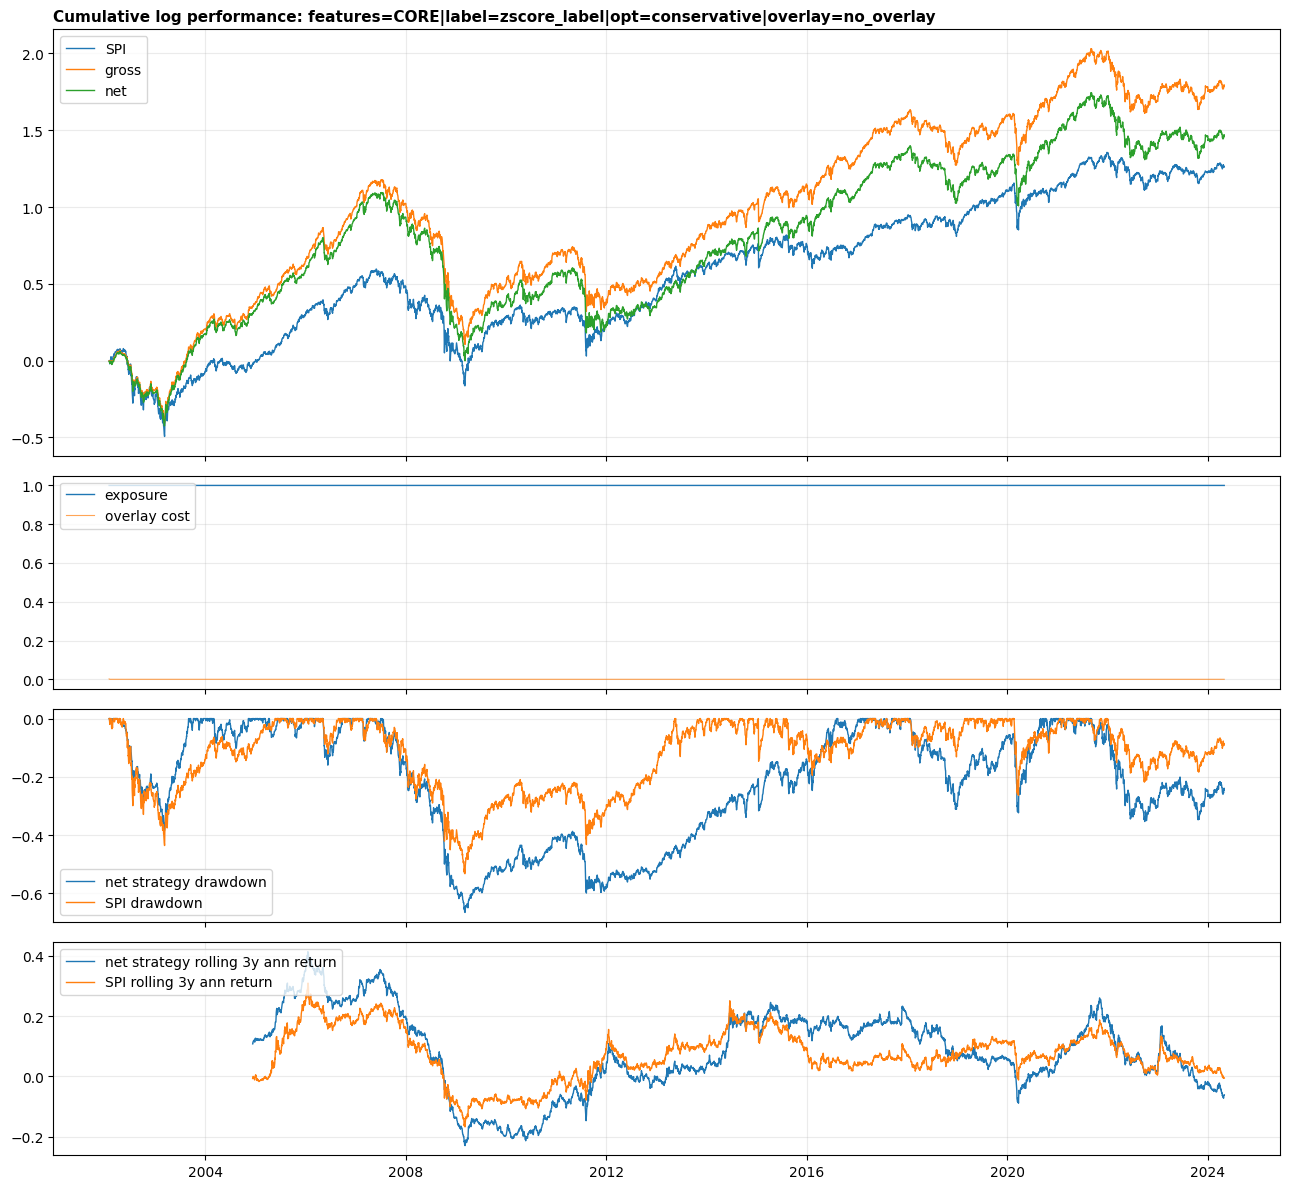


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                         strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.072531 0.160006    0.500502        0.06954  -0.665676       0.035714  0.733747           0.104497       0.187659    0.087677      0.588205

EVALUATE STRATEGY: features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
features=CORE|label=zscore_label|o

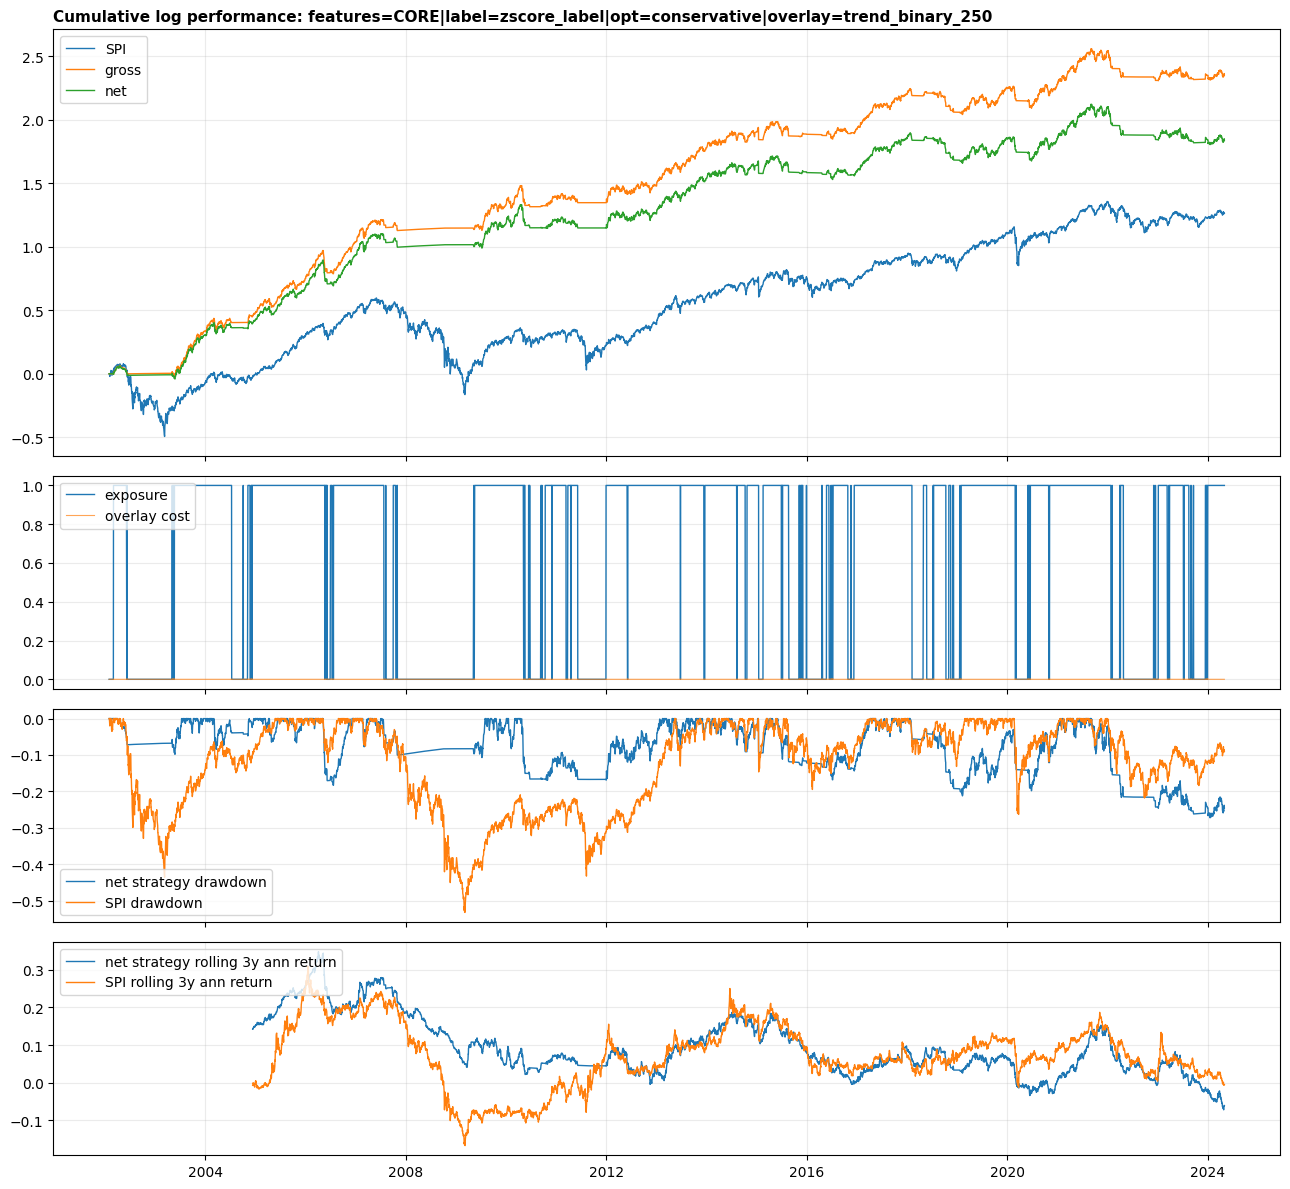


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
      features=CORE|label=zscore


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                             strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.101197 0.107428    0.925358       0.098128  -0.320389       0.075464  0.396073           0.134443       0.289599    0.122894      1.107923
features=CORE|label=zscore_label|opt=c

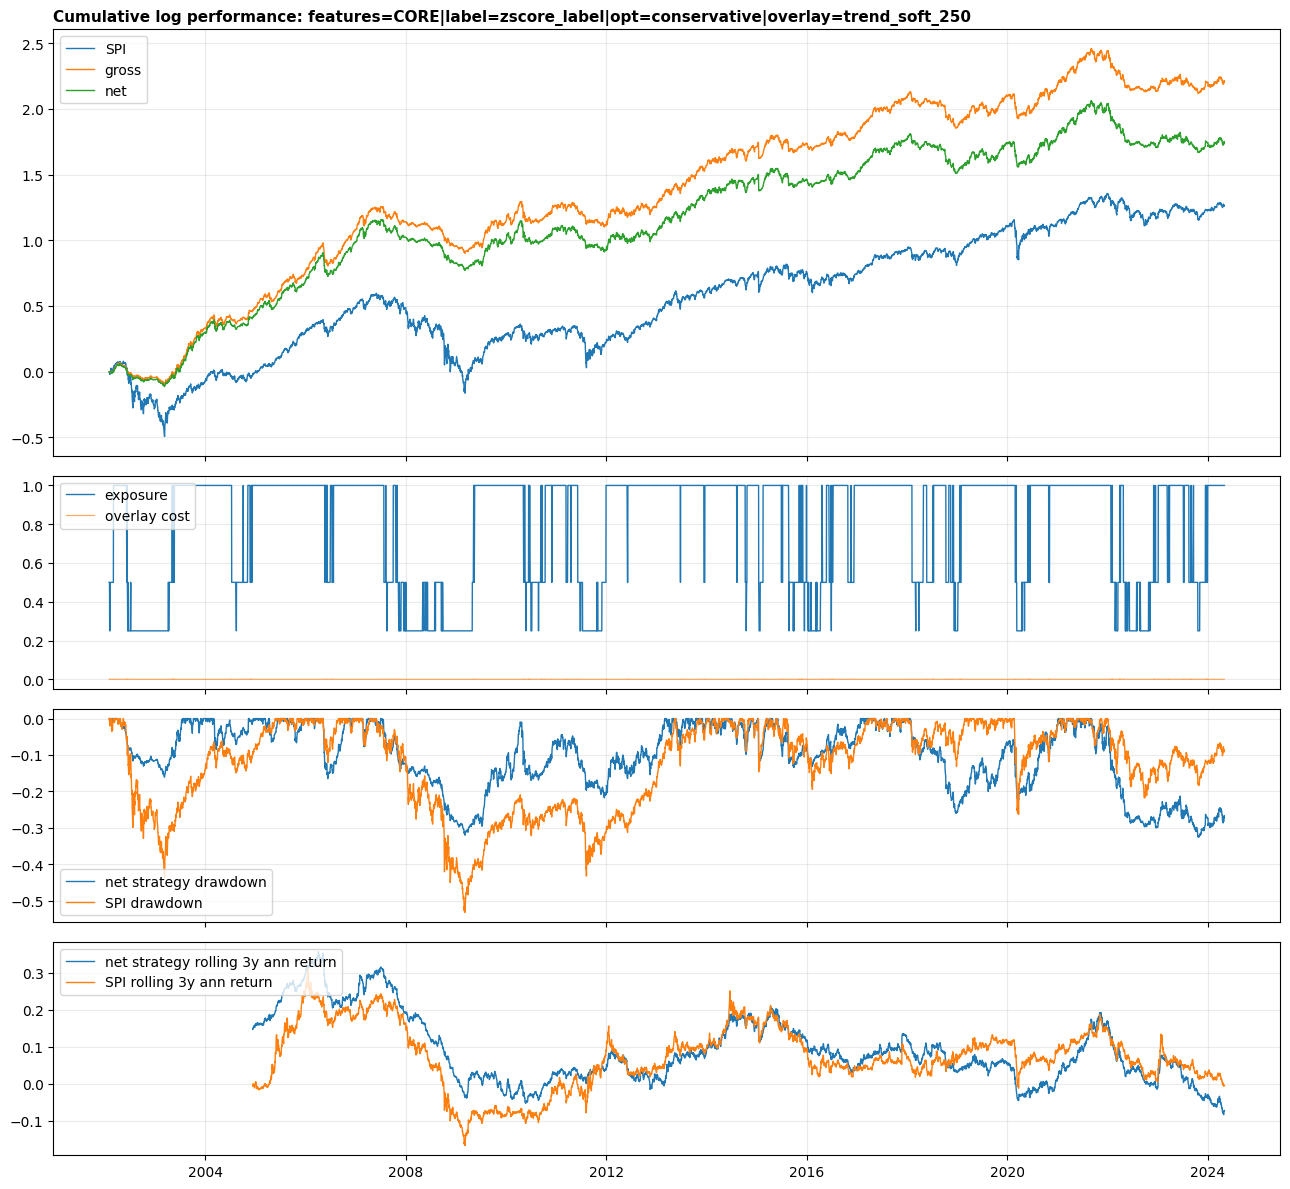


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
  features=CORE|label=zscore_lab


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                 strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=base|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.077877 0.160444    0.530552       0.074872  -0.614101       0.043235  0.692703           0.116780       0.211065    0.093099      0.618027
features=CORE|label=zscore_label|opt=base|overlay=no_overlay  

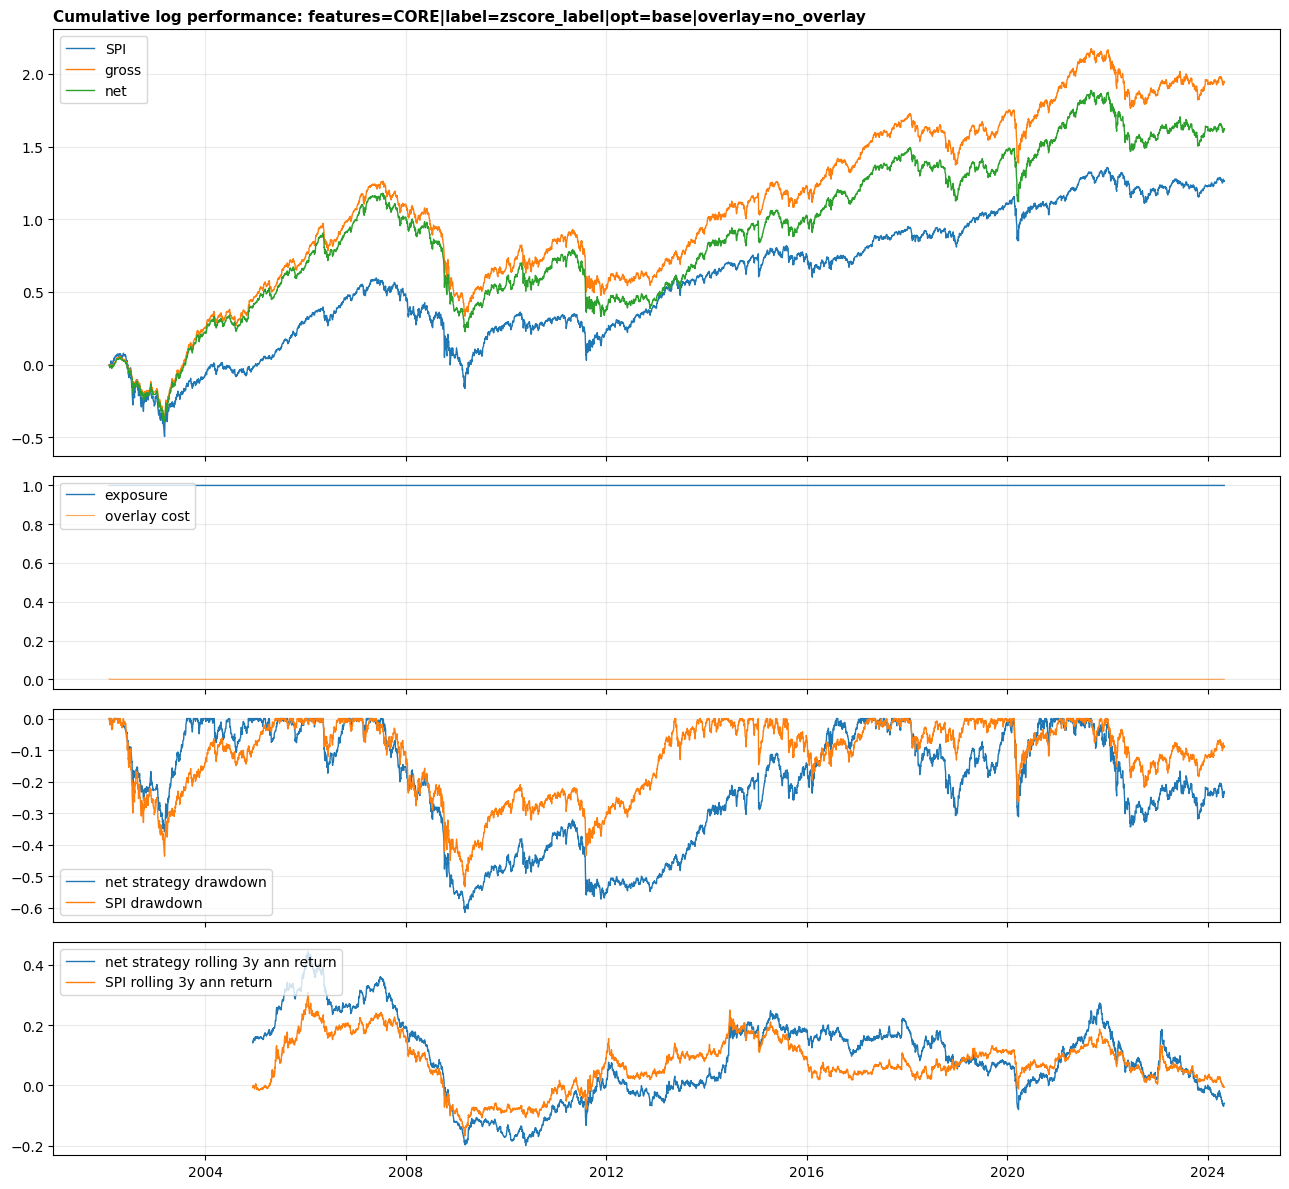


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
  features=CORE|label=zscore_lab


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                       strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.106952 0.103518    1.006789       0.103870  -0.198342       0.089598  0.241718           0.164158       0.266403    0.130863      1.214566
features=CORE|label=zscore_label|opt=base|overlay=

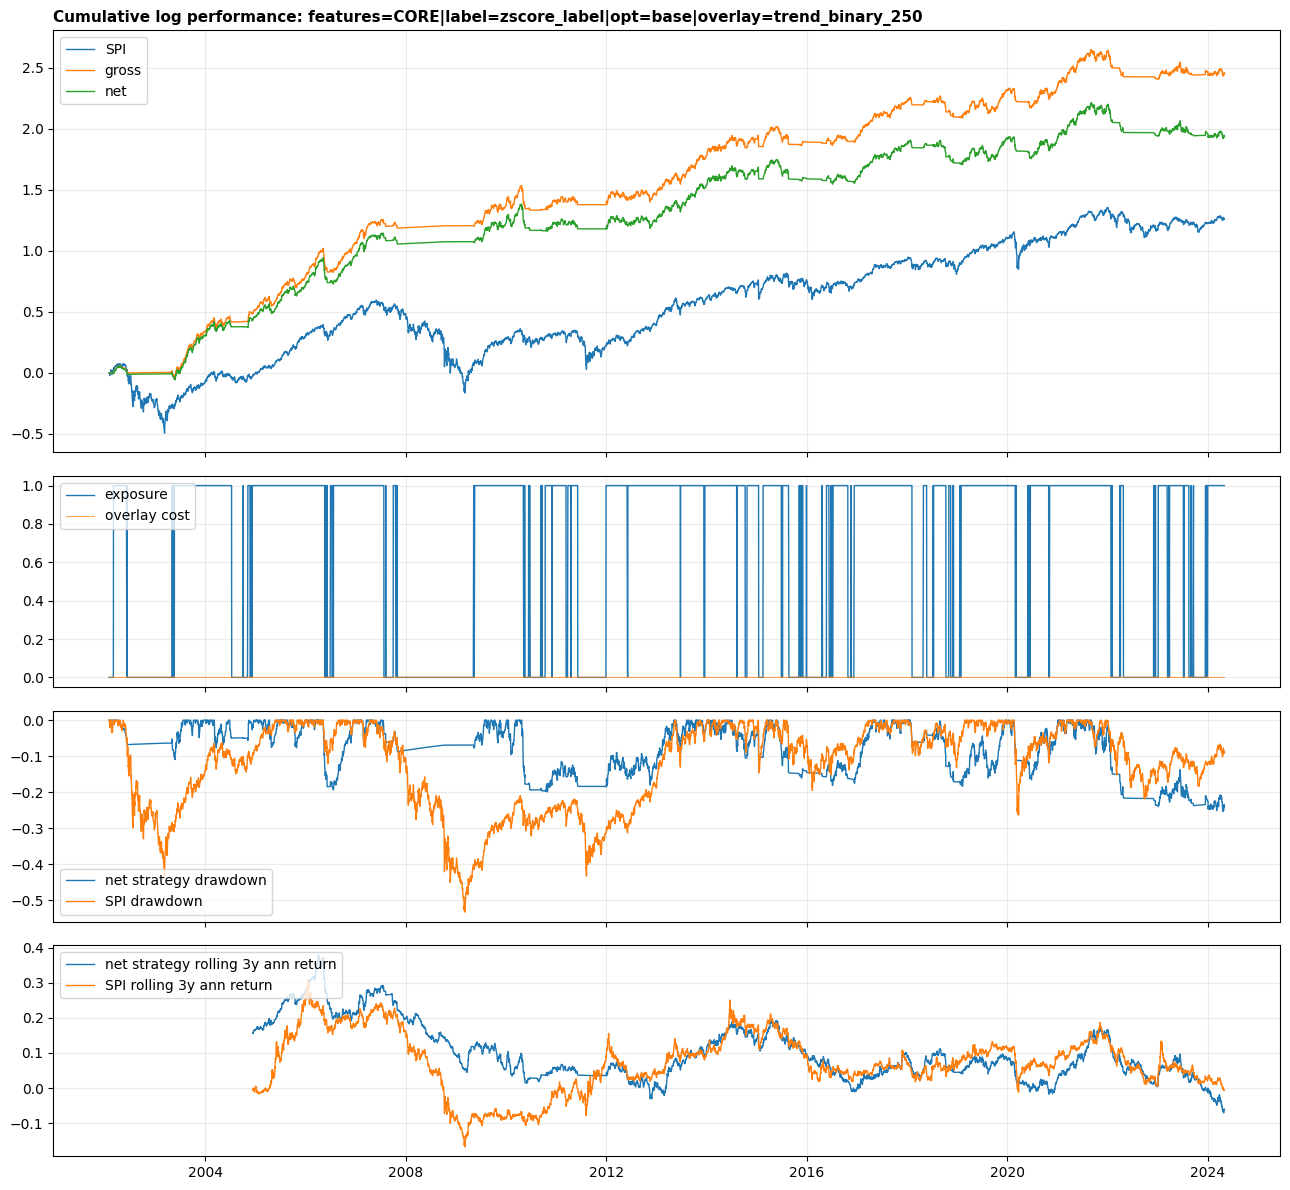


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
        features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                     strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=base|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.103596 0.112044    0.911184       0.100521  -0.287479       0.078836  0.384624           0.140736       0.295687    0.125339      1.086071
features=CORE|label=zscore_label|opt=base|overlay=tren

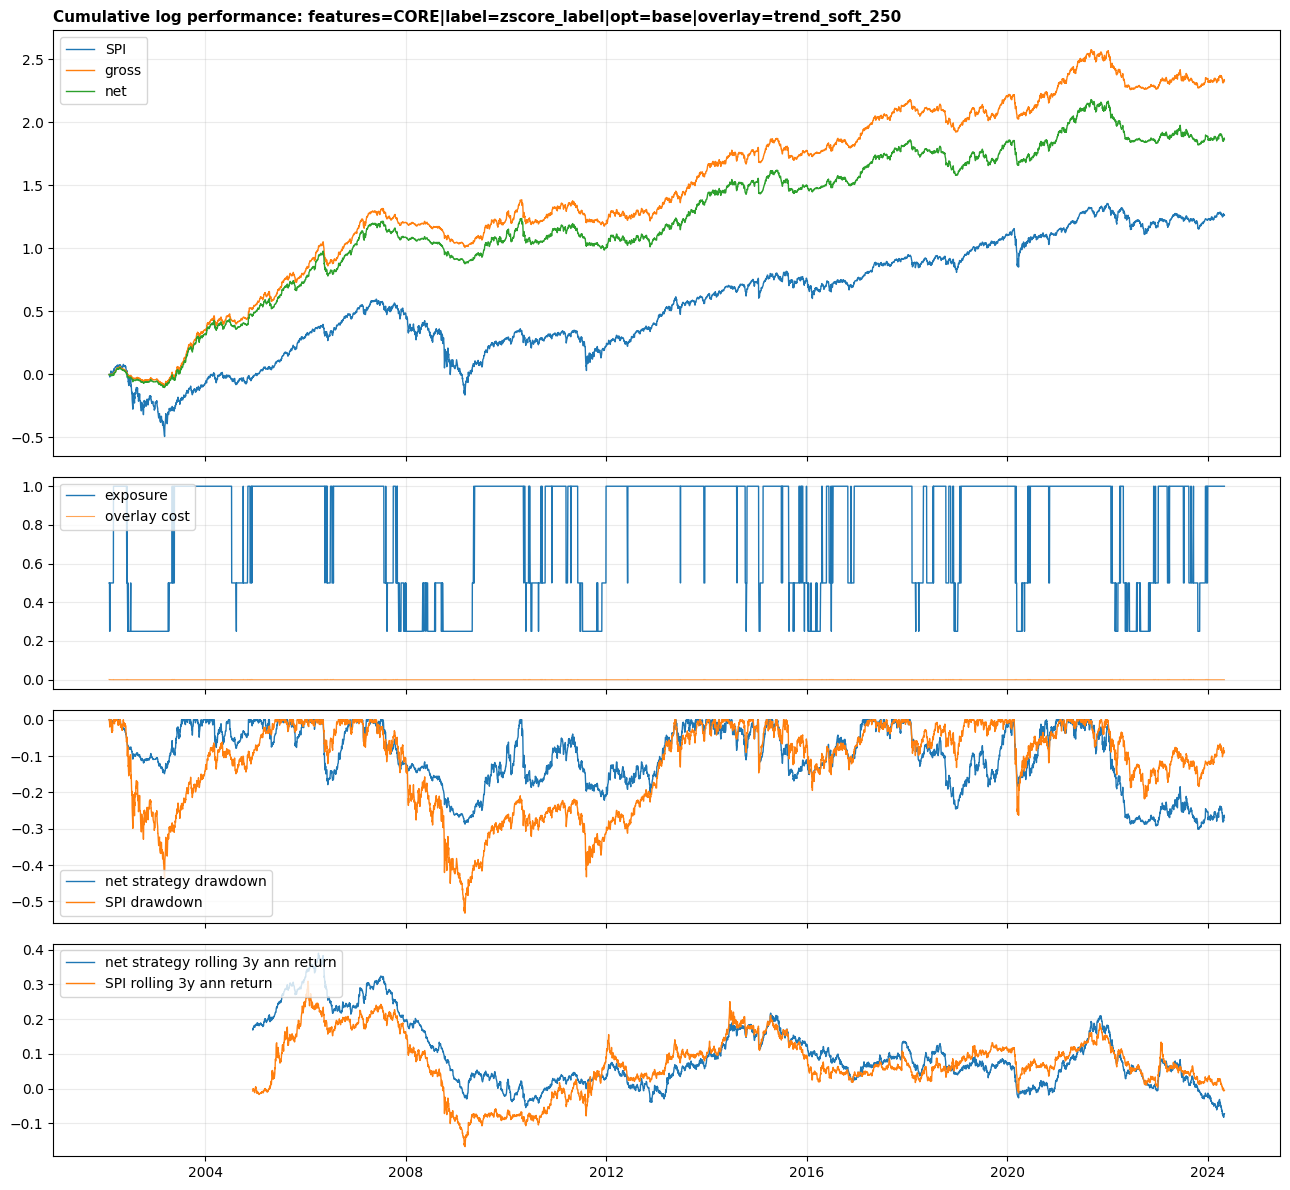


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
        features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                       strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=aggressive|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.089162 0.168229    0.575520       0.086126  -0.597265       0.054795  0.694928           0.126710       0.286812    0.104542      0.658952
features=CORE|label=zscore_label|opt=aggressive|ov

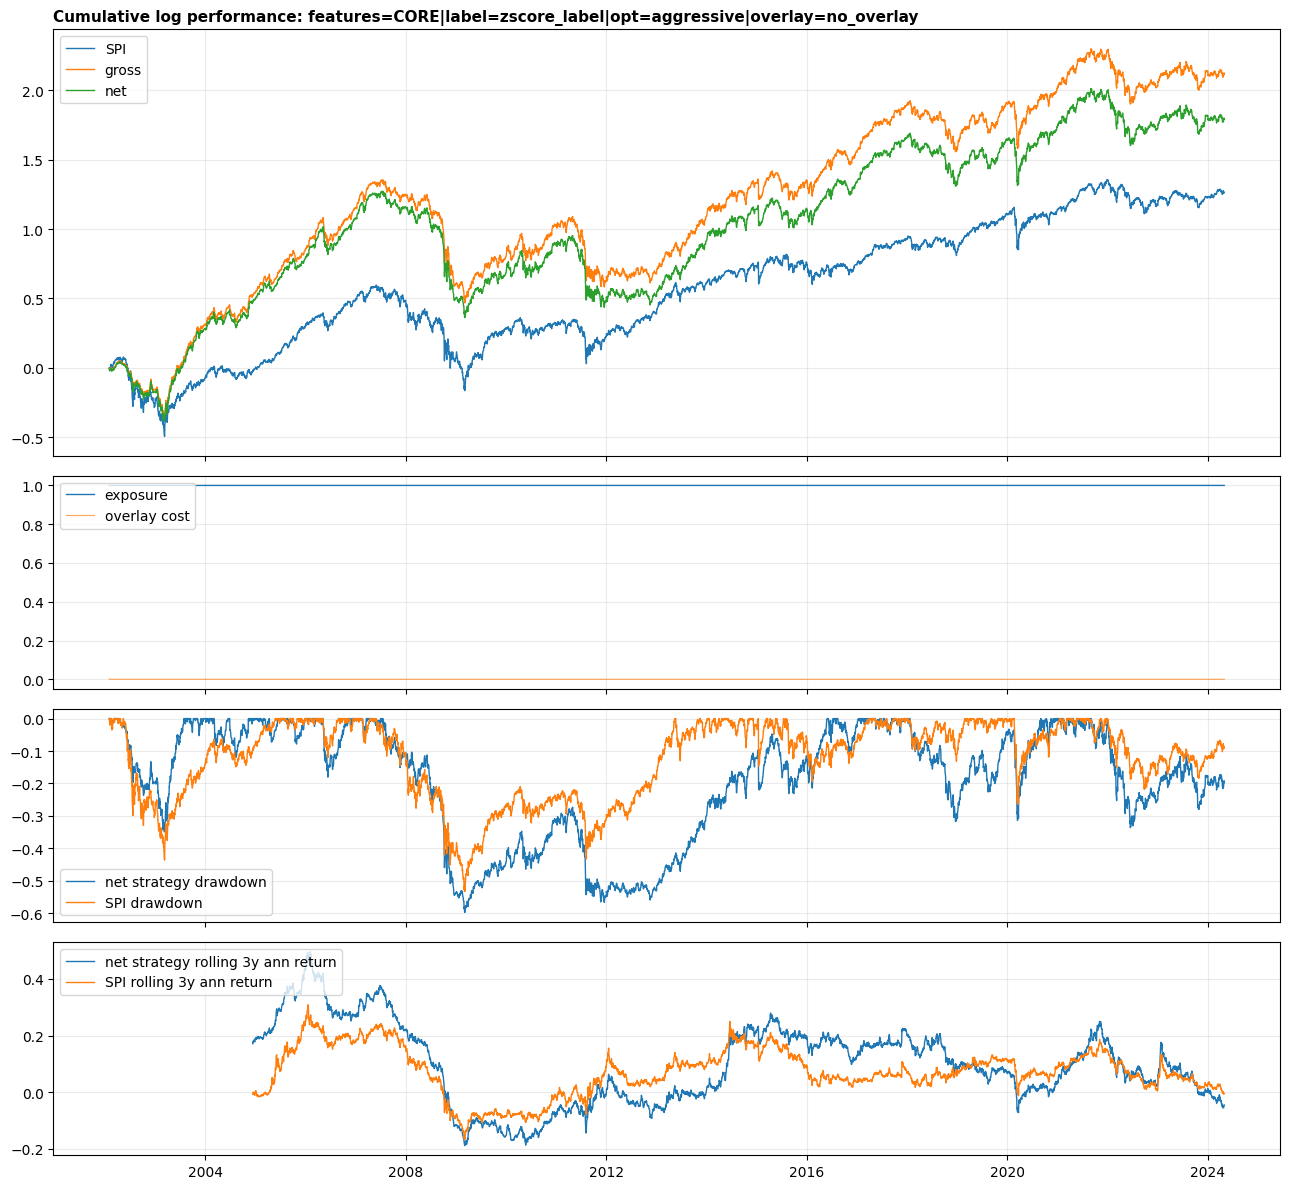


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
        features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Exposure diagnostics
--------------------------------------------------------------------------------------------------------------
                                                             strategy_id          overlay  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost
features=CORE|label=zscore_label|opt=aggressive|overlay=trend_binary_250 trend_binary_250       0.670867             0.670867             0.329133                0.02537               0.298


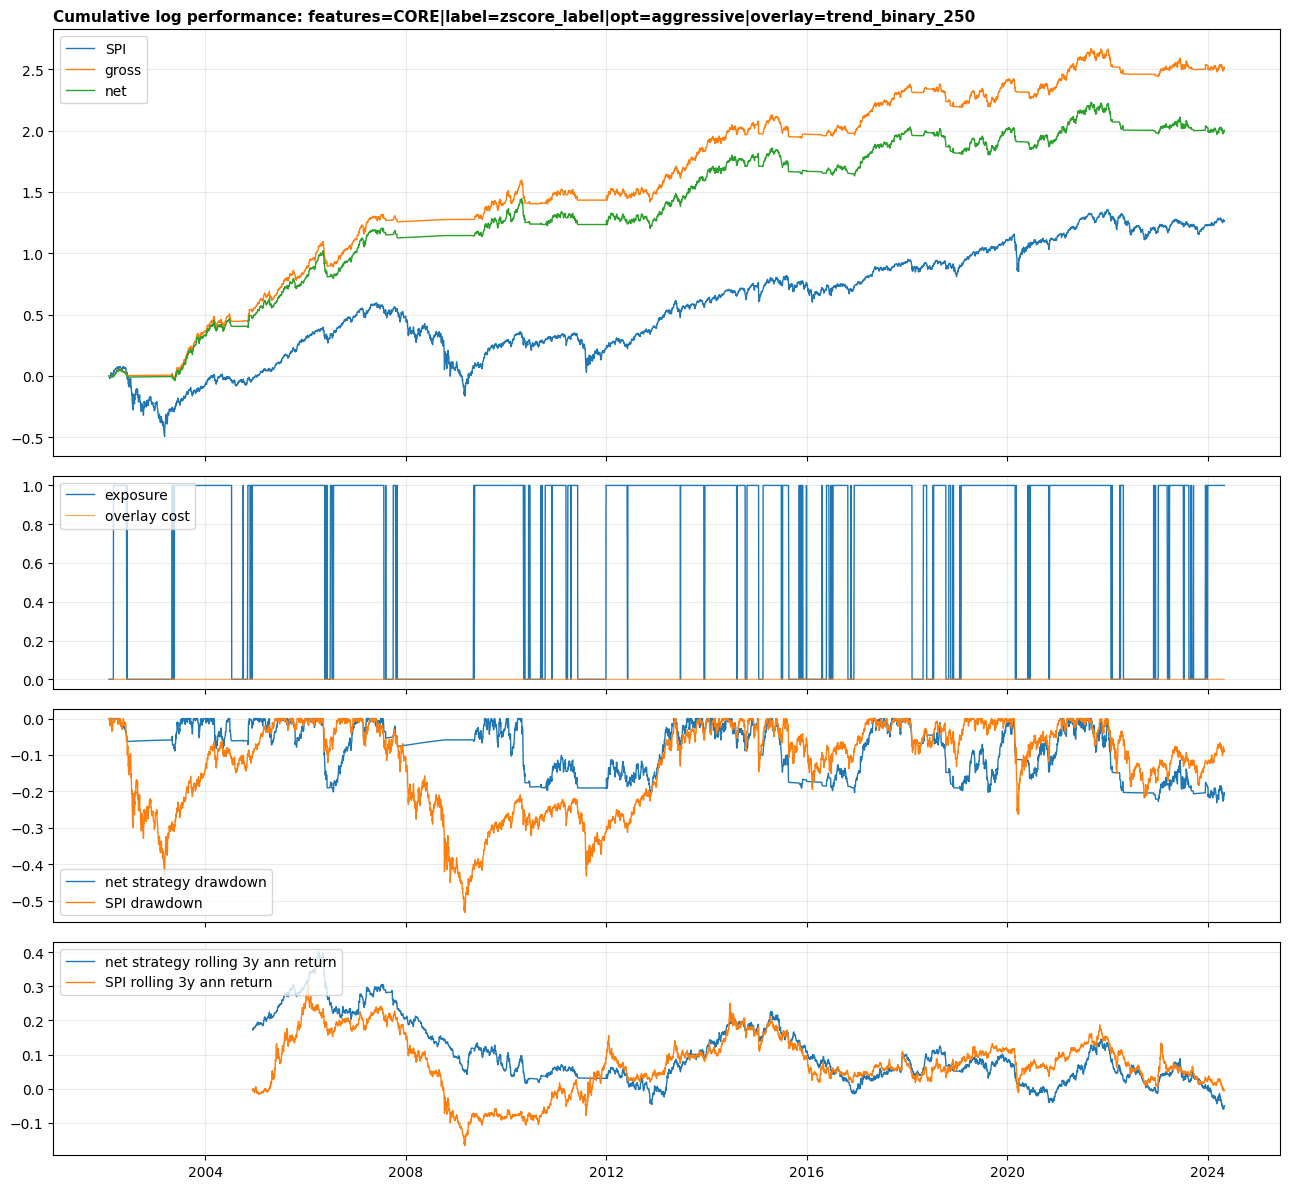


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
        features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                           strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=aggressive|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.111164 0.118374    0.926357       0.108069  -0.271703       0.086346  0.385468           0.145642       0.337645    0.133054      1.091708
features=CORE|label=zscore_label|opt=aggre

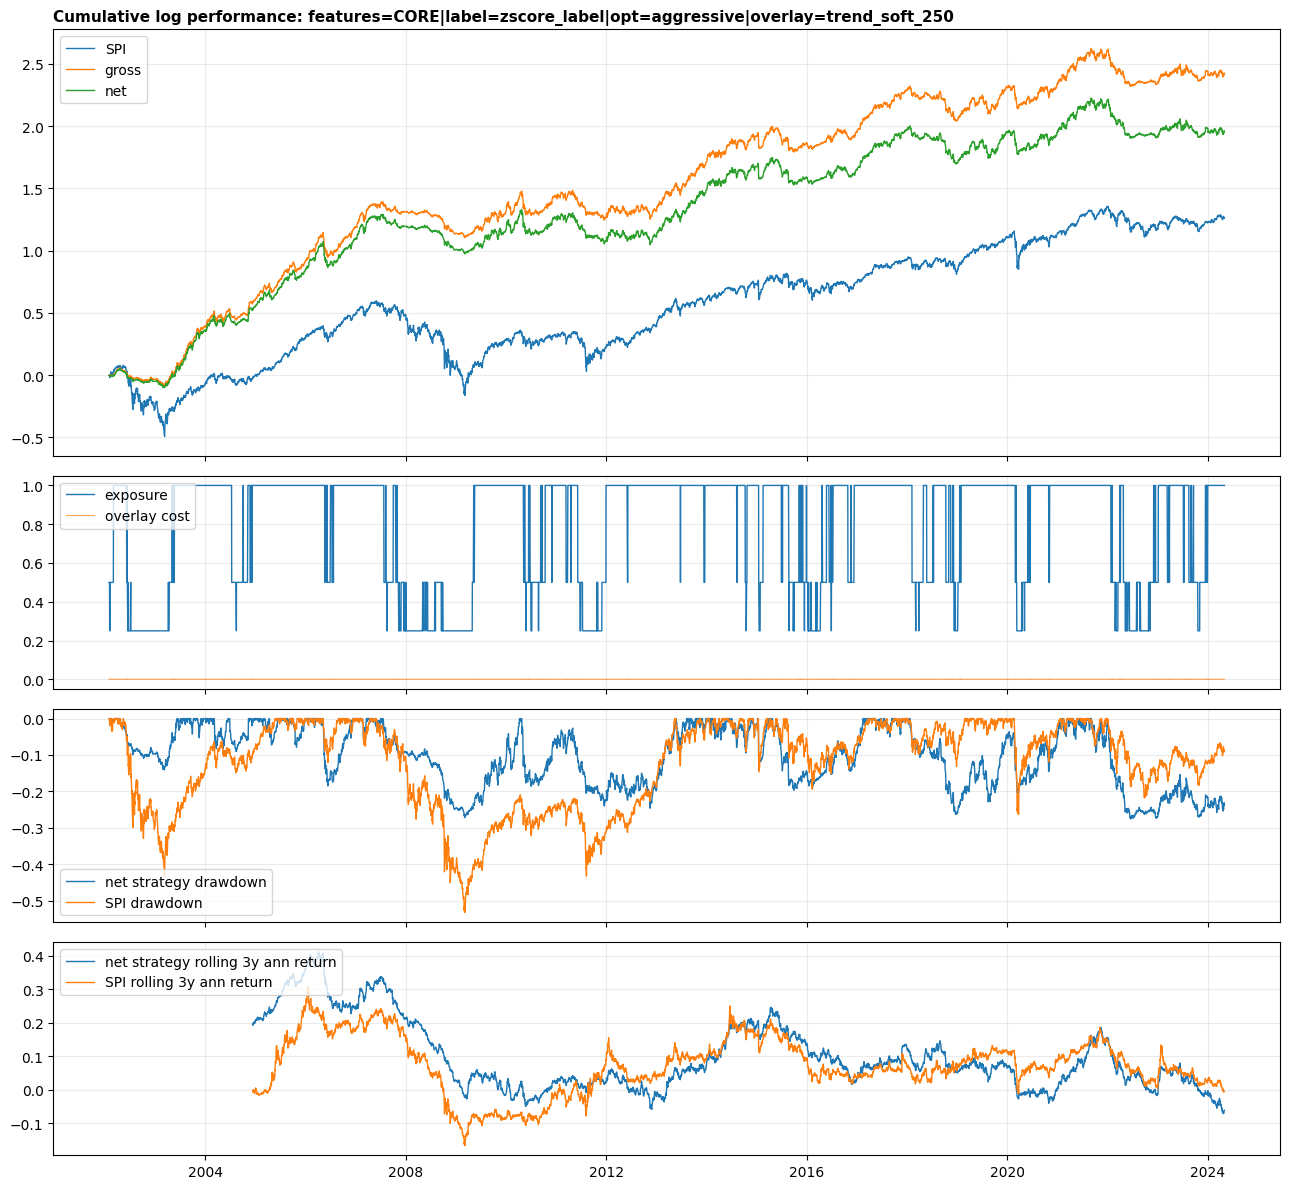


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
        features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                       strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=conservative|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.081719 0.153784    0.569841       0.078702  -0.605419       0.044598  0.711704           0.101743       0.266943    0.096994      0.661099
features=CORE|label=rank_label|opt=conservative|ov

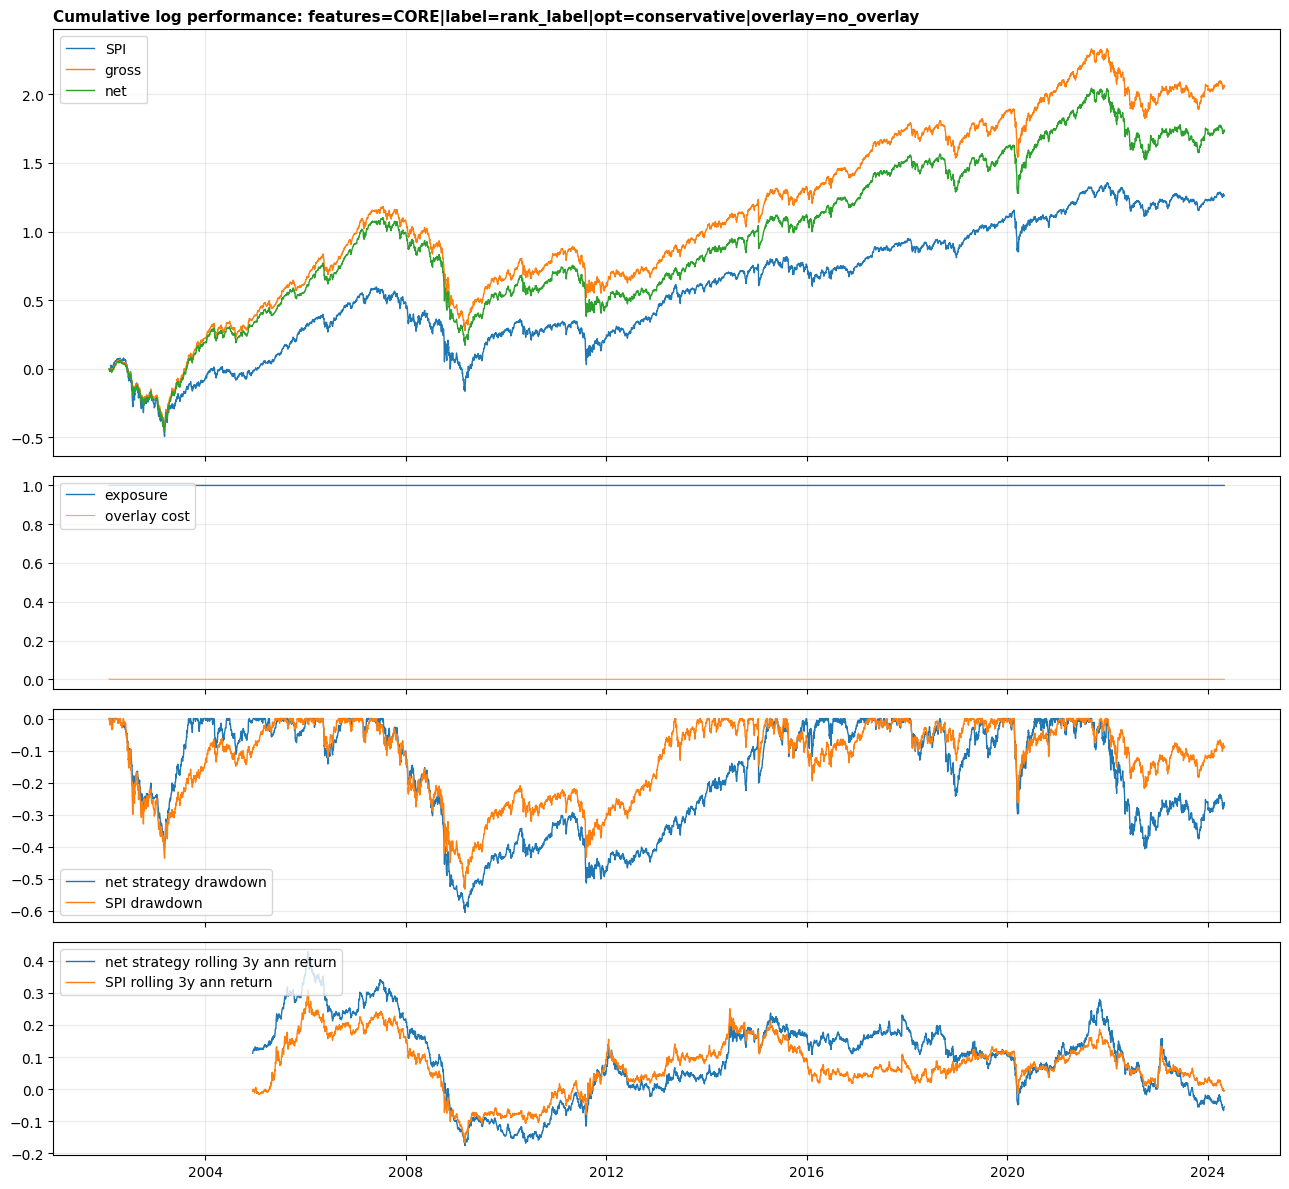


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107175 0.098439    1.055591       0.104092  -0.183315       0.089260  0.242223           0.160906       0.269878    0.131092      1.274259
        features=CORE|label=zsco


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                             strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=rank_label|opt=con

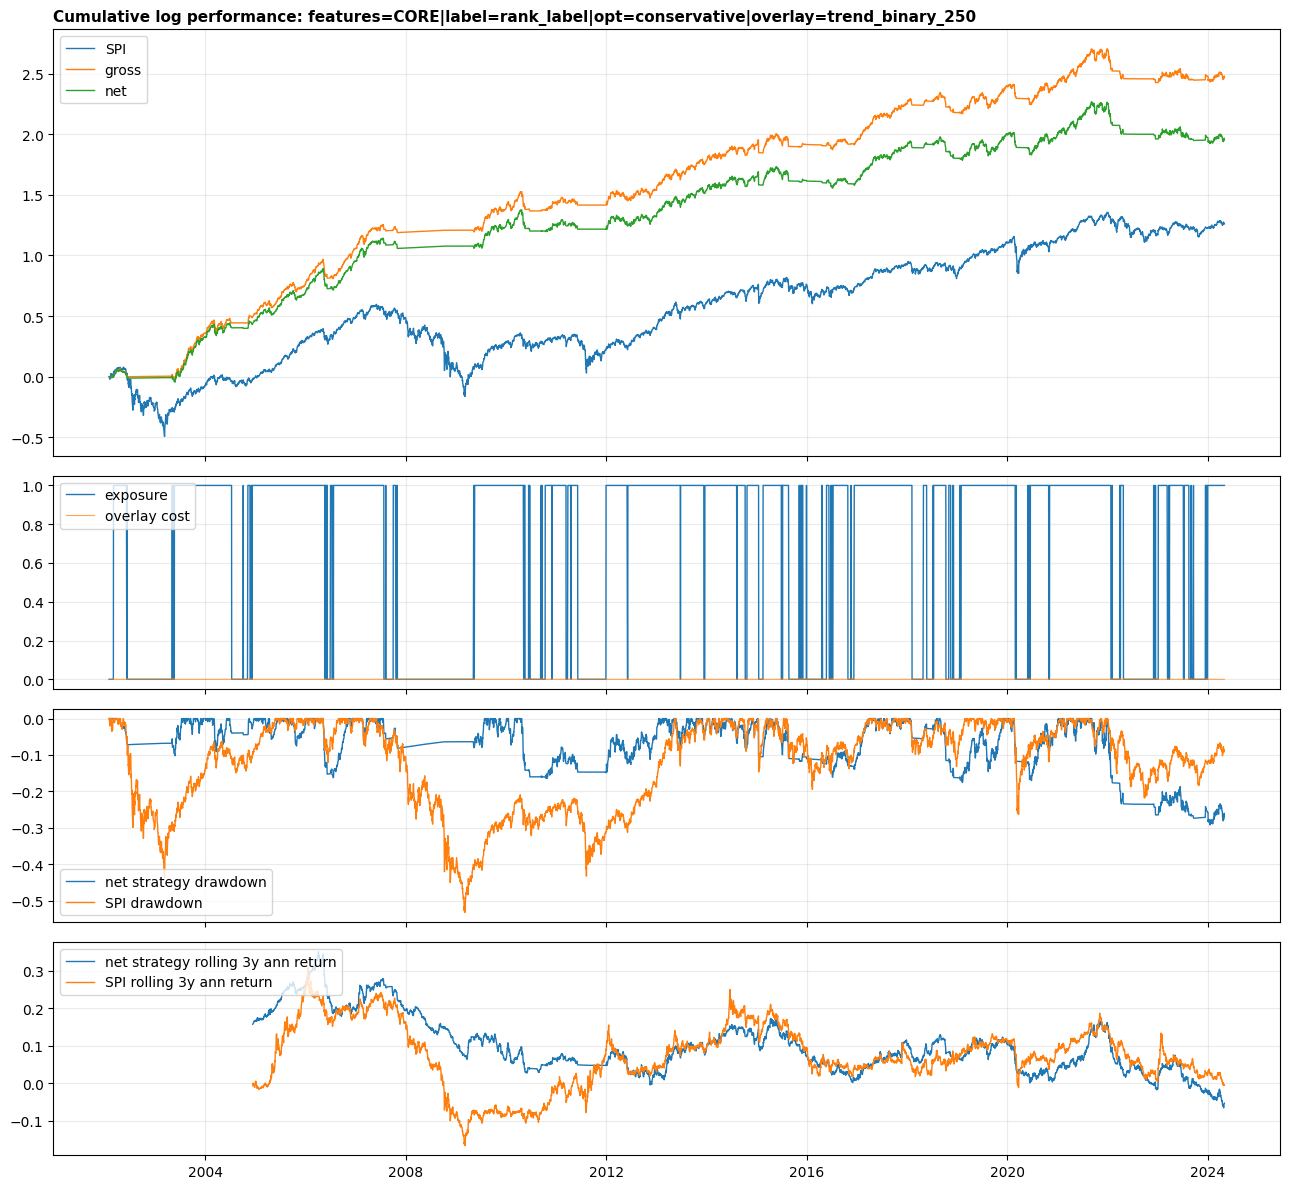


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                           strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=conservative|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.104715 0.104678    0.977397       0.101637  -0.270965       0.078854  0.388000           0.134159       0.311844    0.126479      1.164628
features=CORE|label=rank_label|opt=conserv

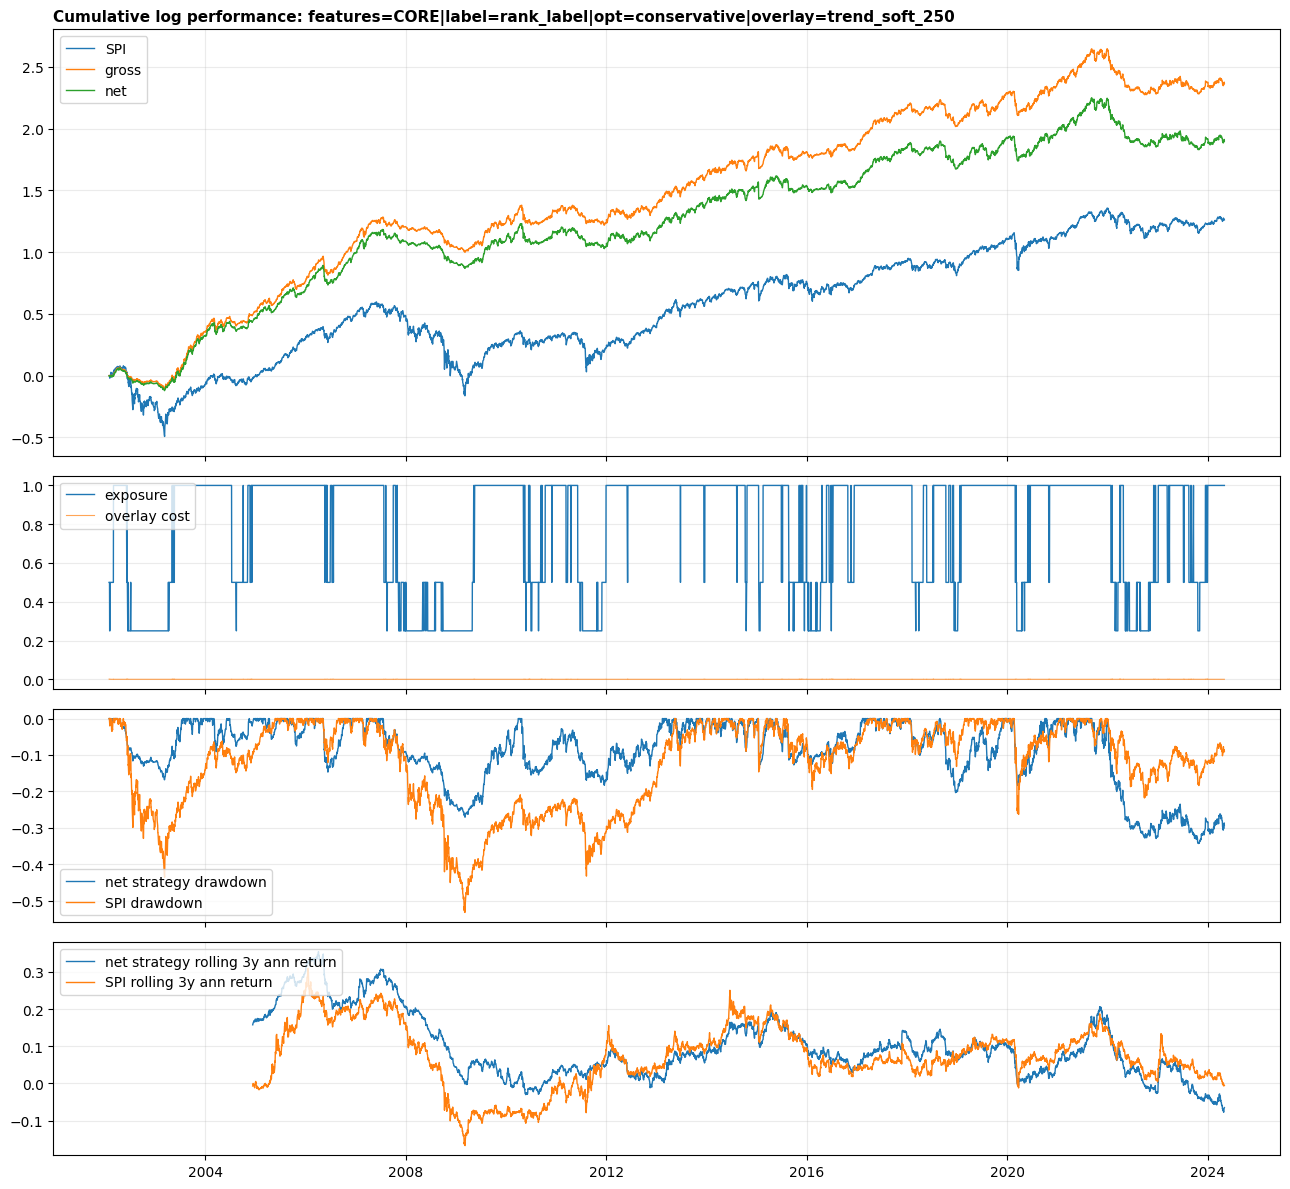


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=base|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.084443 0.156655    0.578305       0.081420  -0.583354       0.049375  0.681657           0.114588       0.262854    0.099757      0.667896
features=CORE|label=rank_label|opt=base|overlay=no_overlay       t

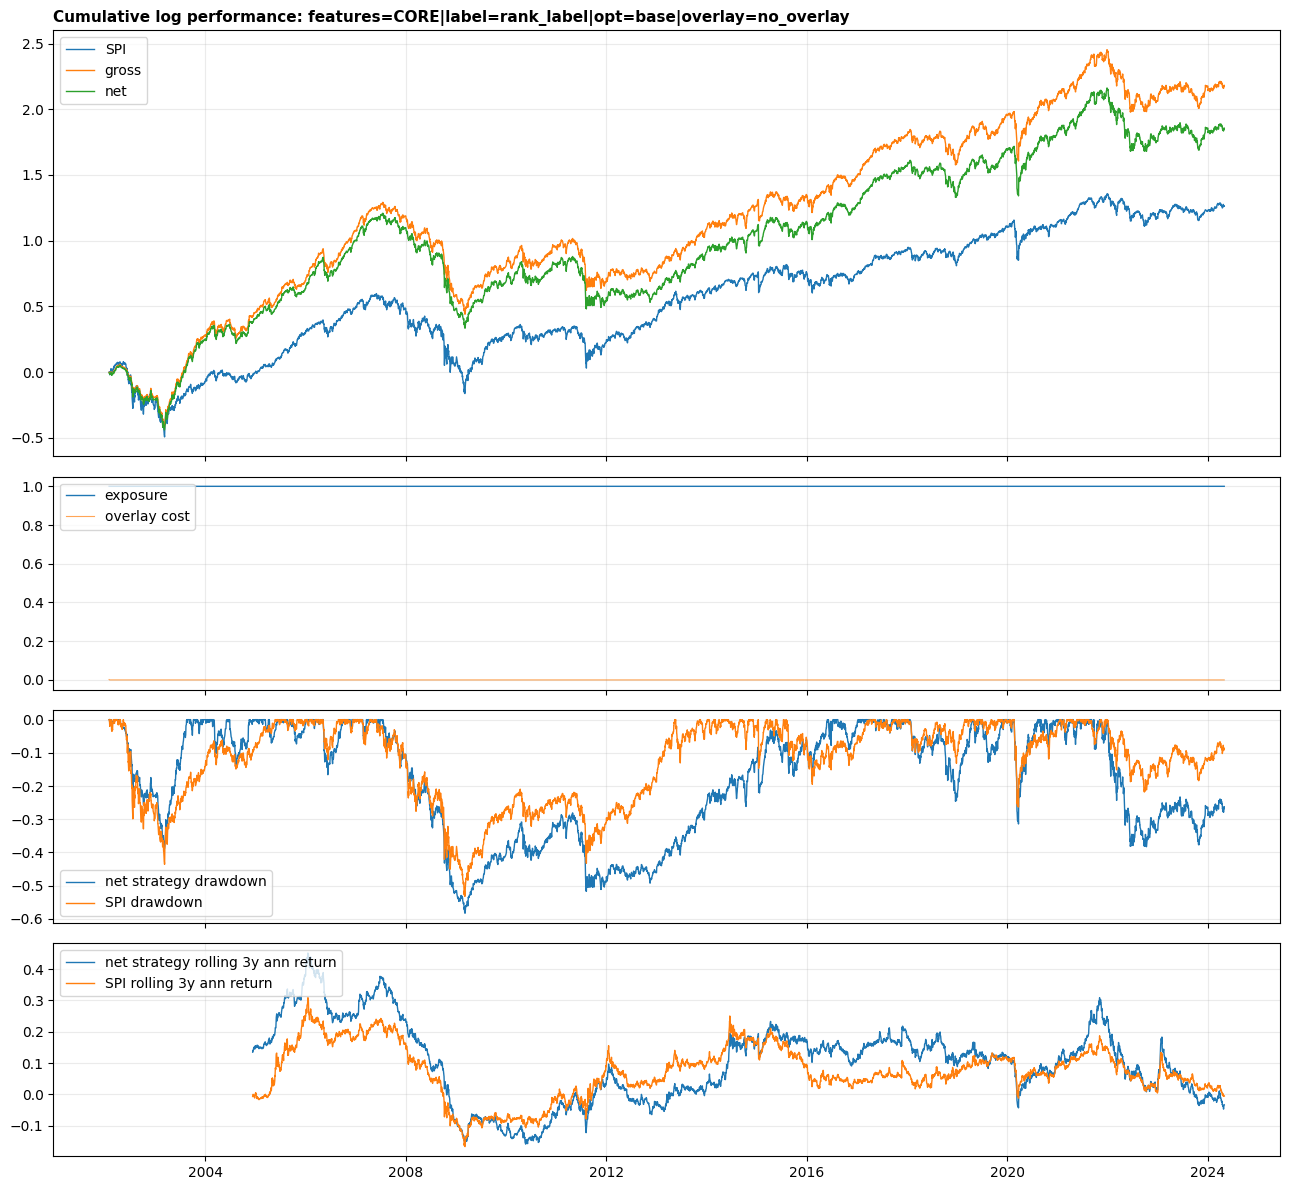


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                     strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.109926 0.103163    1.035964       0.106836  -0.186226       0.092240  0.241875           0.163904       0.282995    0.133896      1.243926
features=CORE|label=rank_label|opt=base|overlay=trend_

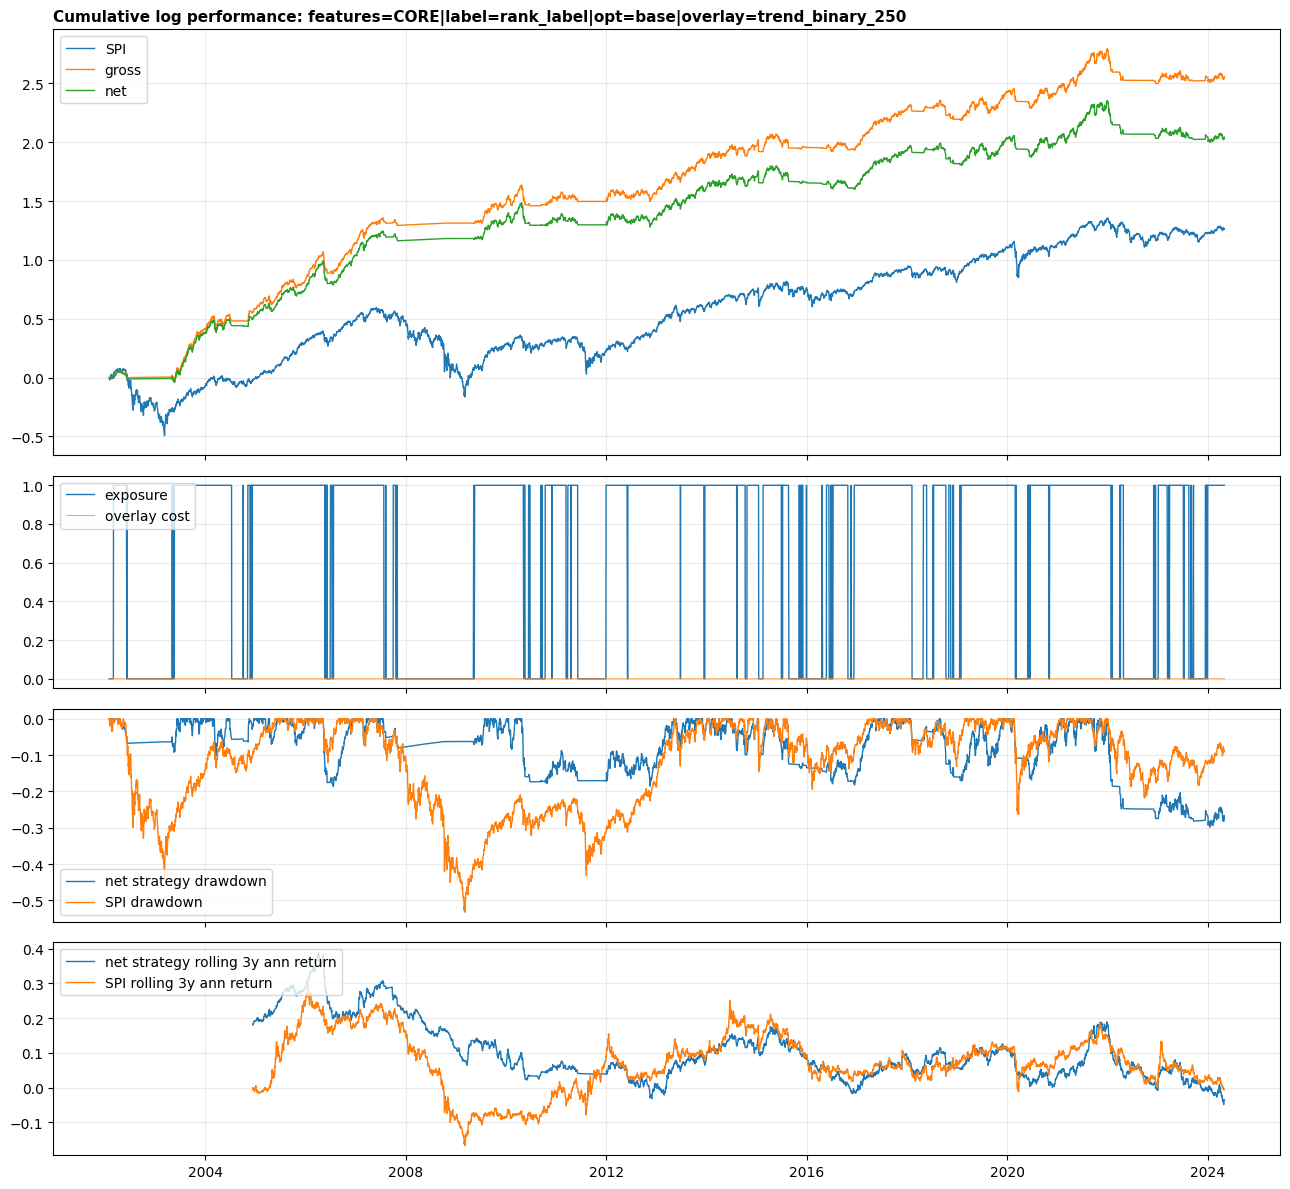


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=base|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.106697 0.111186    0.942654       0.103615  -0.258690       0.081746  0.381406           0.140773       0.314904    0.128498      1.118649
features=CORE|label=rank_label|opt=base|overlay=trend_soft

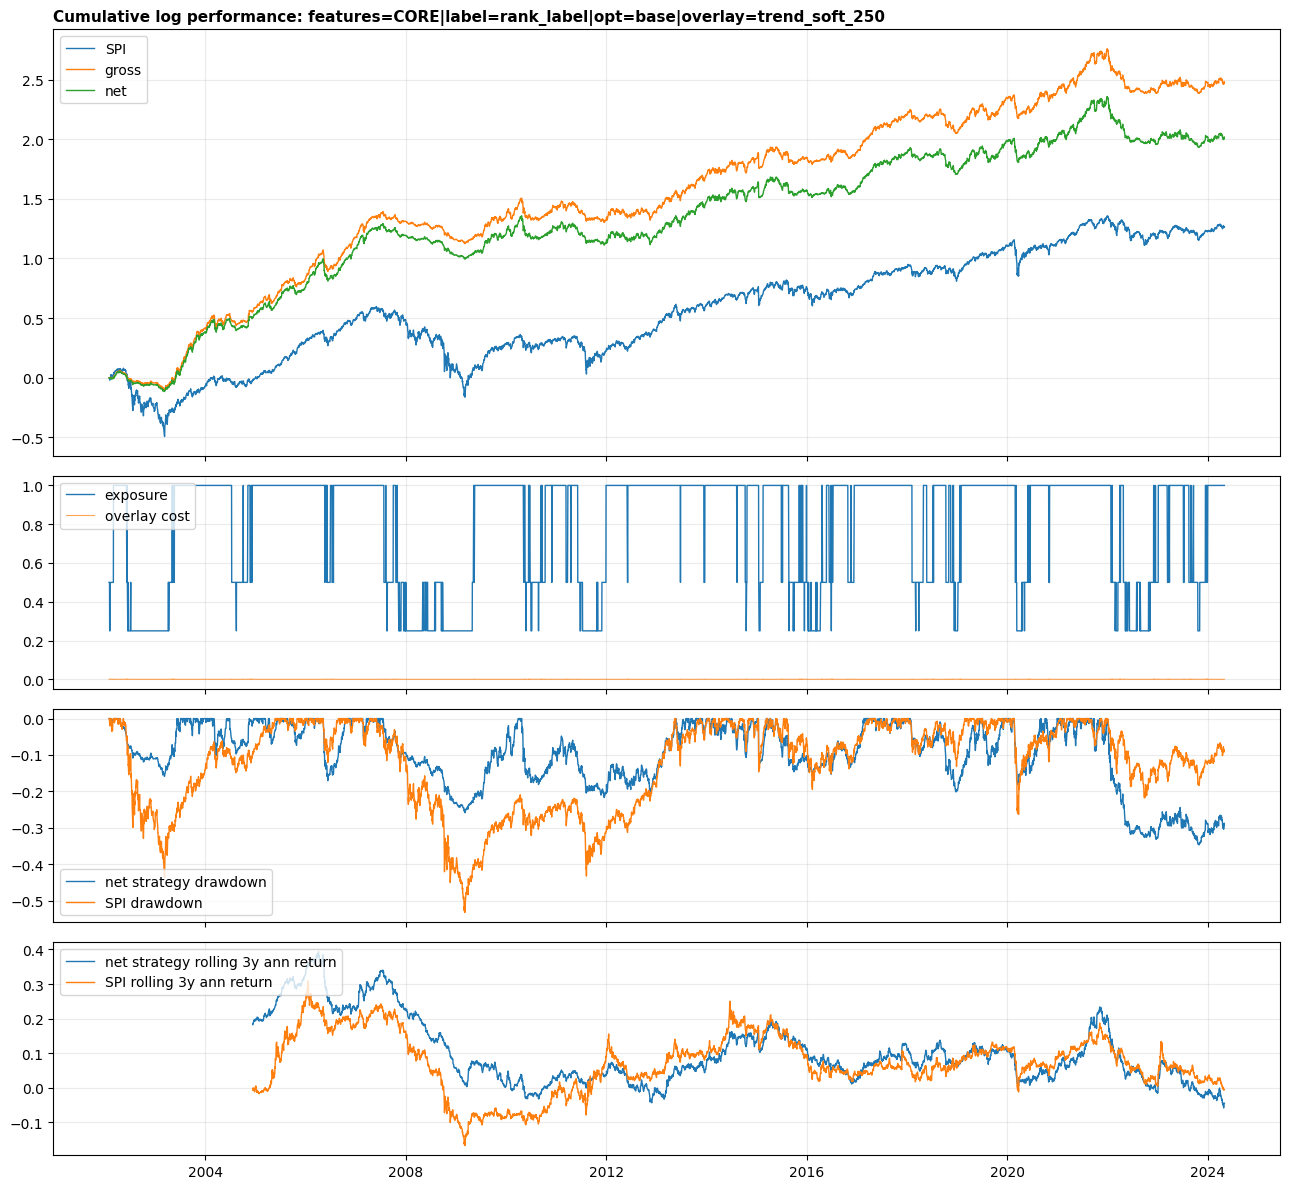


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                     strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=aggressive|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.069113 0.165332    0.470330       0.066132  -0.613514       0.035845  0.693114           0.123303       0.140163    0.084210      0.555200
features=CORE|label=rank_label|opt=aggressive|overlay=

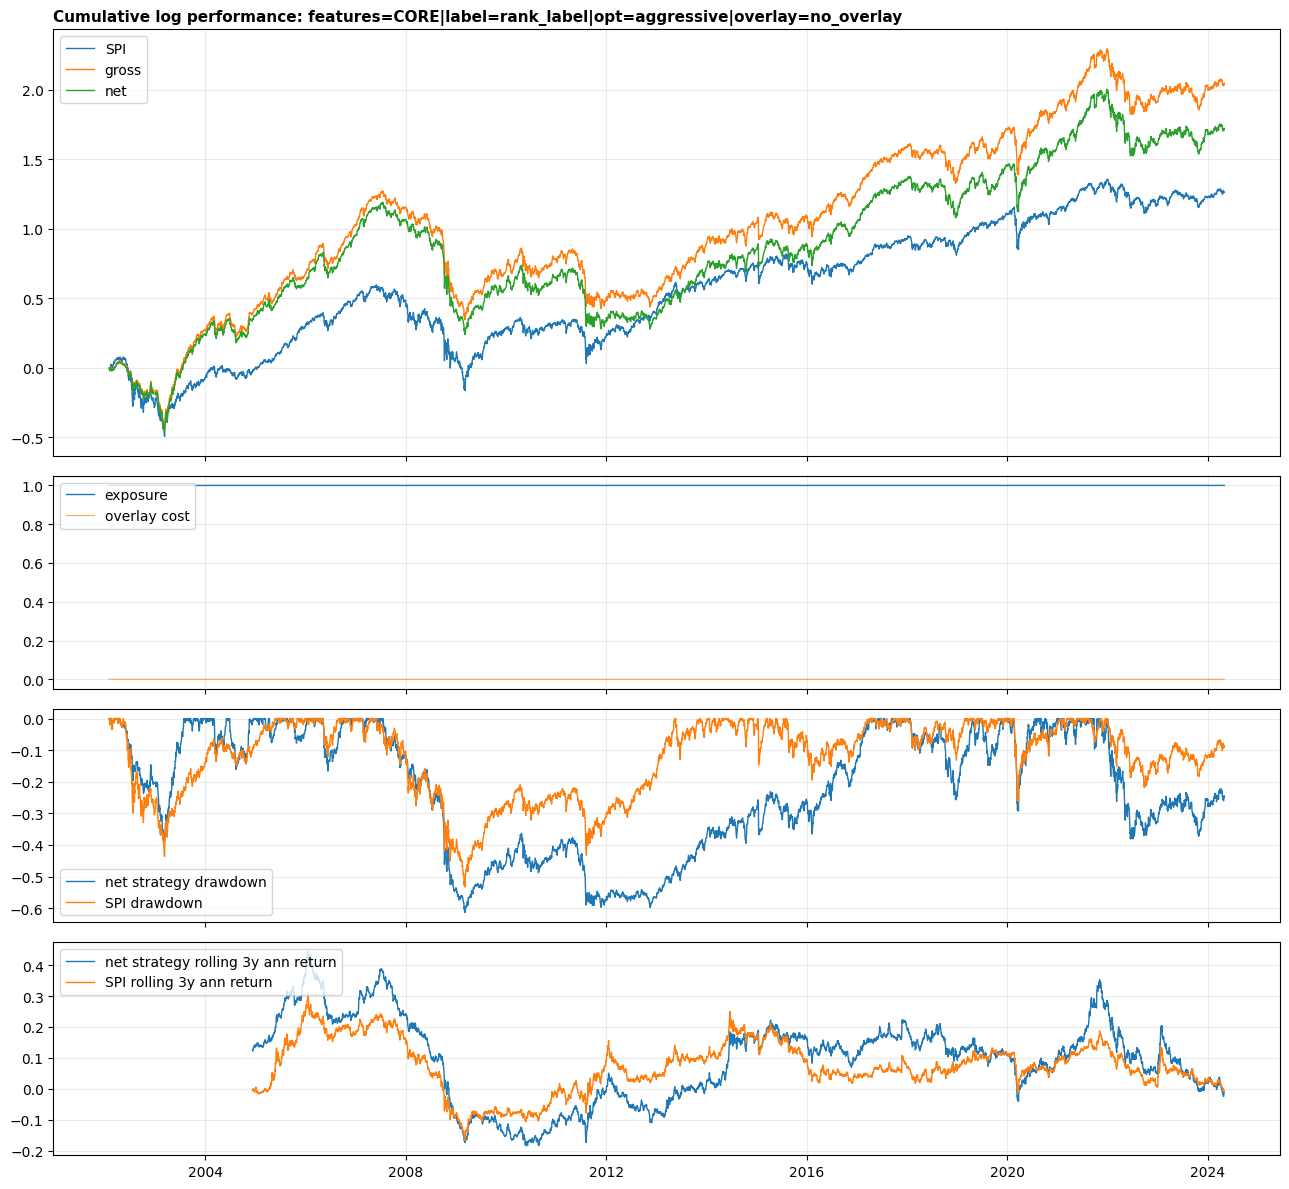


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                           strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=aggressive|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.107825 0.107965    0.977001       0.104740  -0.231818       0.090979  0.239690           0.167377       0.268801    0.131750      1.175667
features=CORE|label=rank_label|opt=aggress

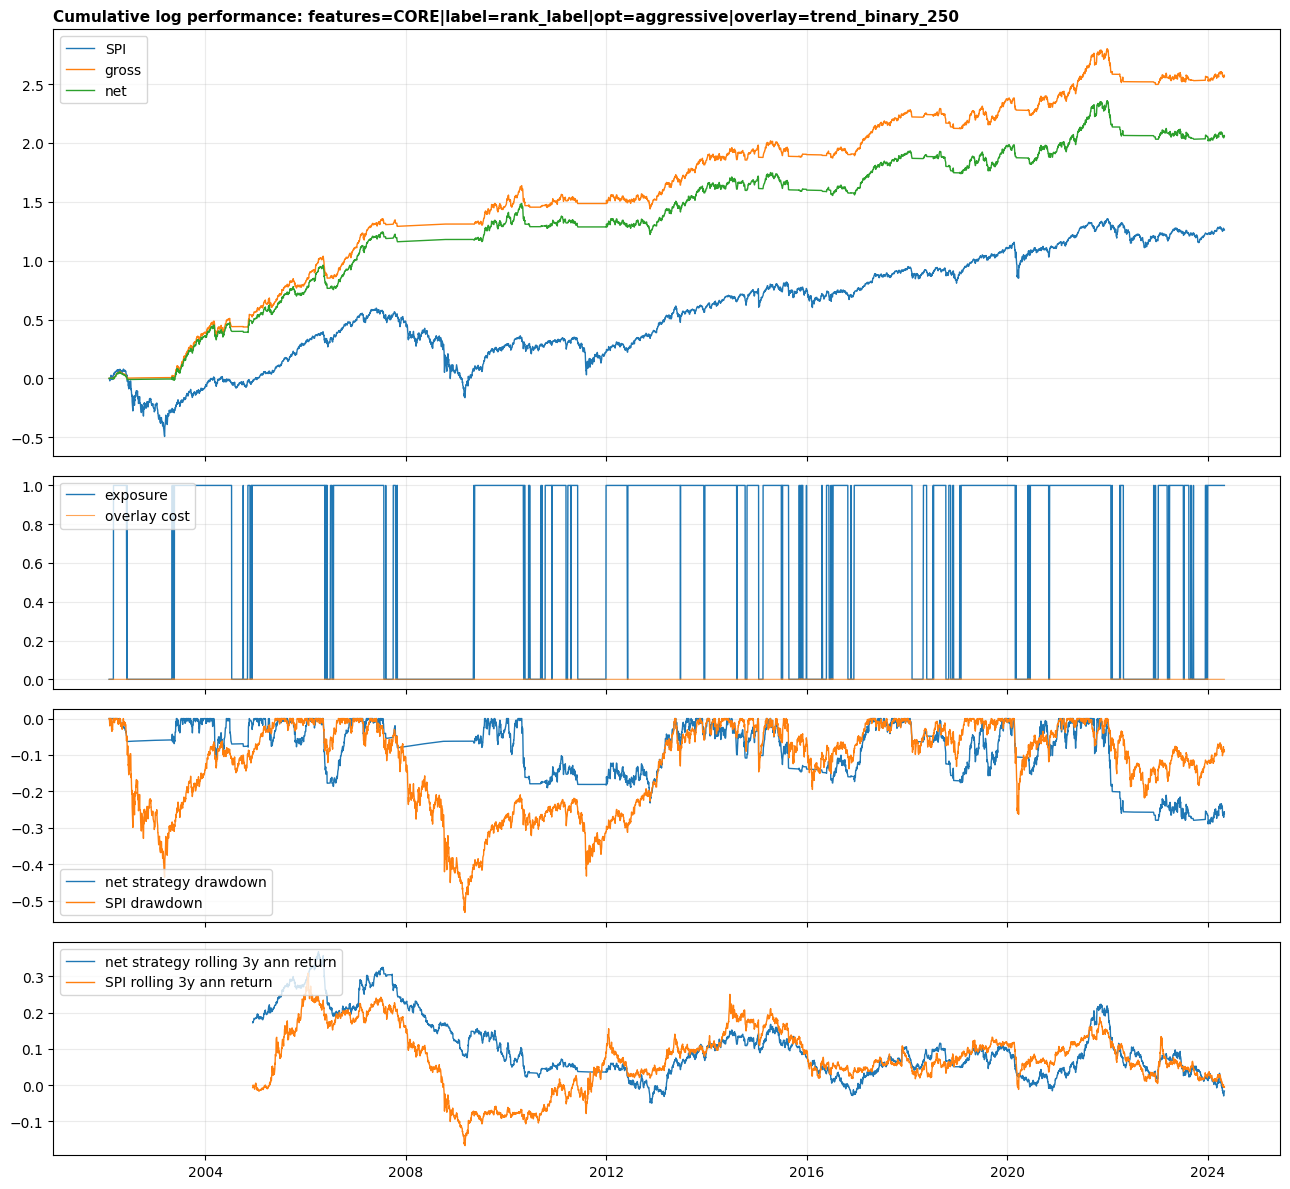


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                         strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=CORE|label=rank_label|opt=aggressive|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.100155 0.116440    0.854297       0.097090  -0.282688       0.076352  0.382349           0.144753       0.269372    0.121826      1.022248
features=CORE|label=rank_label|opt=aggressive|

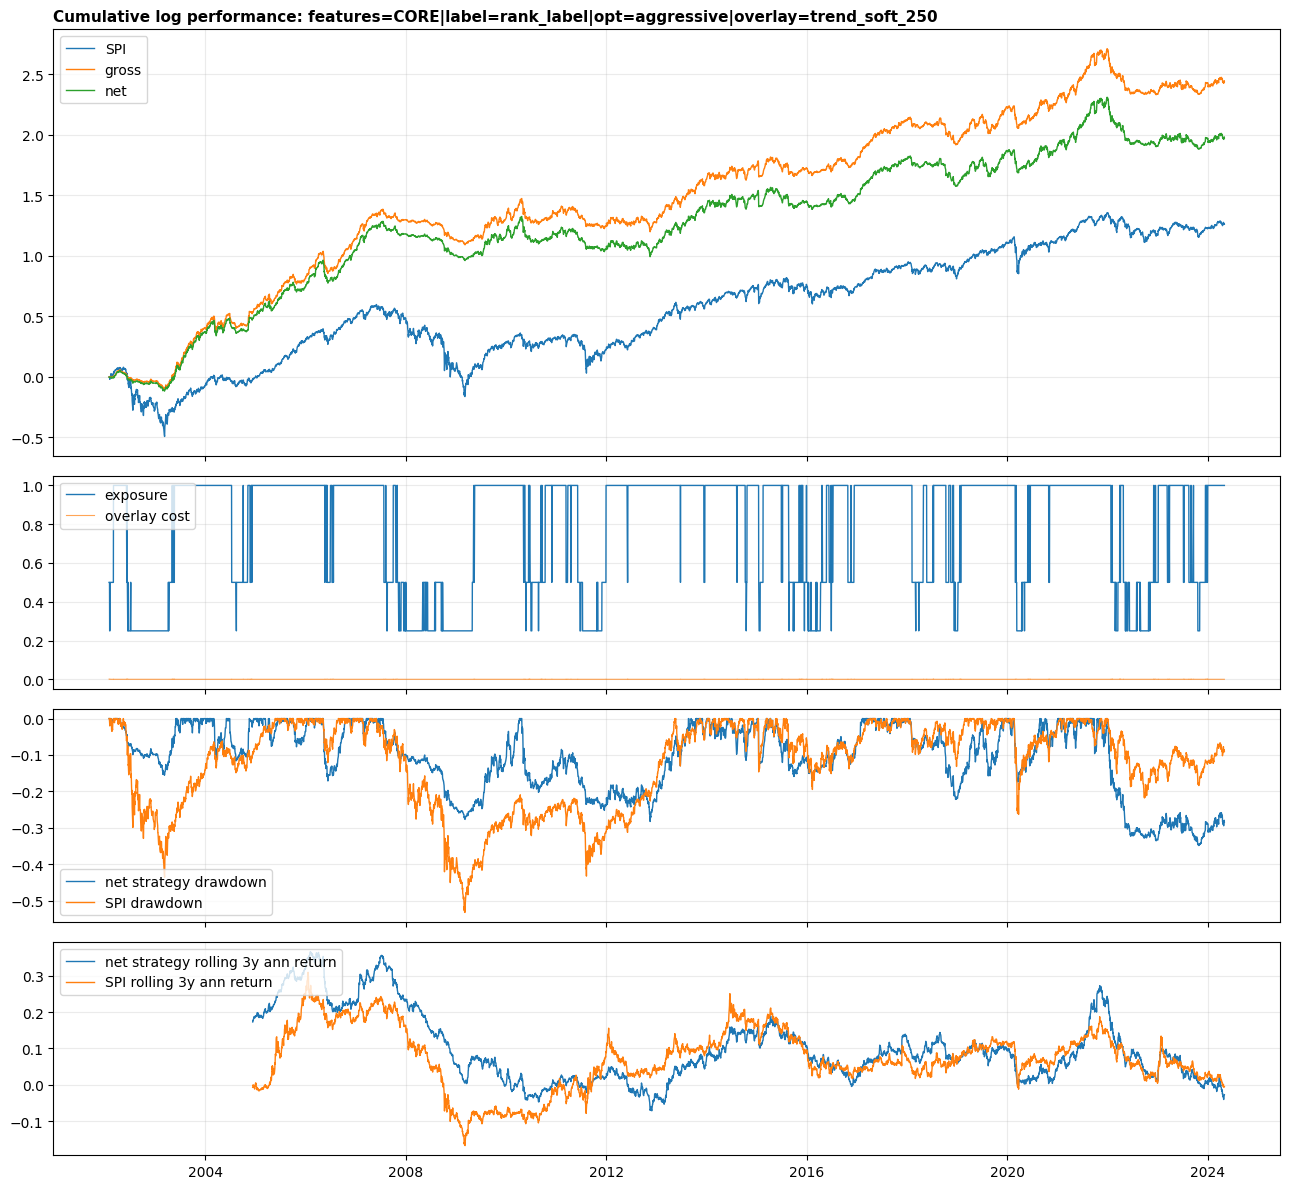


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                             strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=conservative|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.087504 0.164536    0.575460       0.084471  -0.641693       0.049102  0.753792           0.105494       0.324285    0.102860      0.660752
features=EXPANDED|label=zscore_label|o

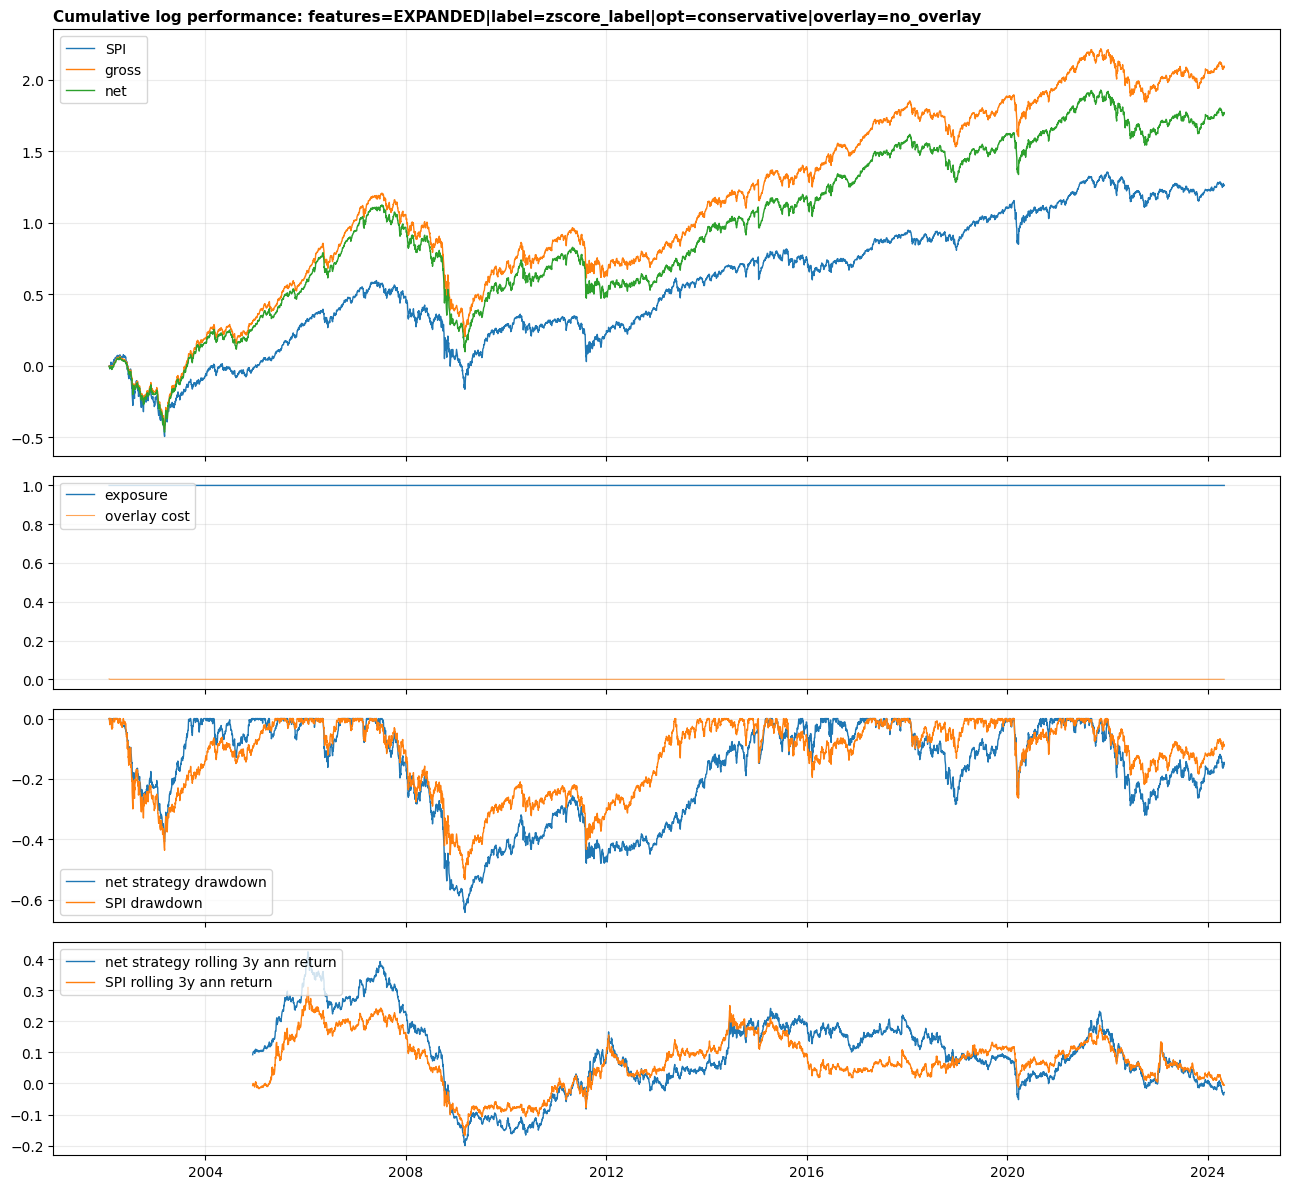


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
  features=CORE|label=rank_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.108787 0.096311    1.091890       0.105699  -0.164331       0.090636  0.240140           0.160023       0.279181    0.132735      1.315185
features=CORE|label=zscore_label


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.116096 0.102493    1.096138       0.112988  -0.186361       0.097005  0.253603           0.161214       0.321674    0.140202      1.305849
features=EXPANDED|label=zs

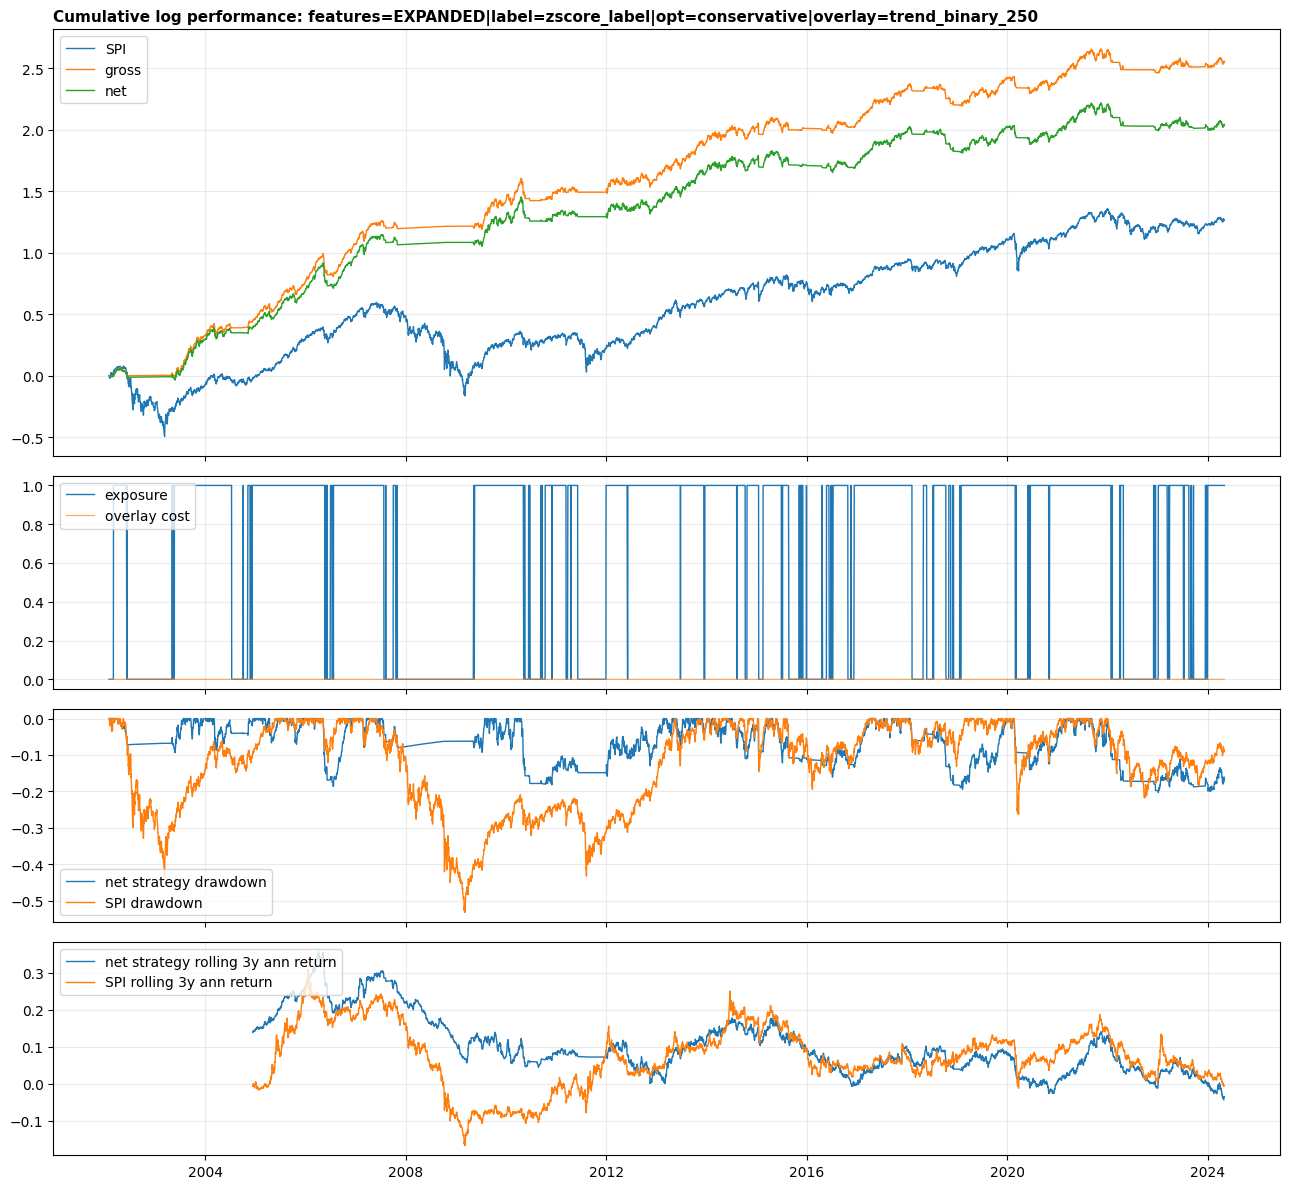


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.116096 0.102493    1.096138       0.112988  -0.186361       0.097005  0.253603           0.161214       0.321674    0.140202      1.305849
      features=CORE|labe


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                                 strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=conservative|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.112460 0.111569    0.986334       0.109361  -0.287483       0.085251  0.410023           0.134552       0.368379    0.134377      1.162030
features=EXPANDED|label=zscore

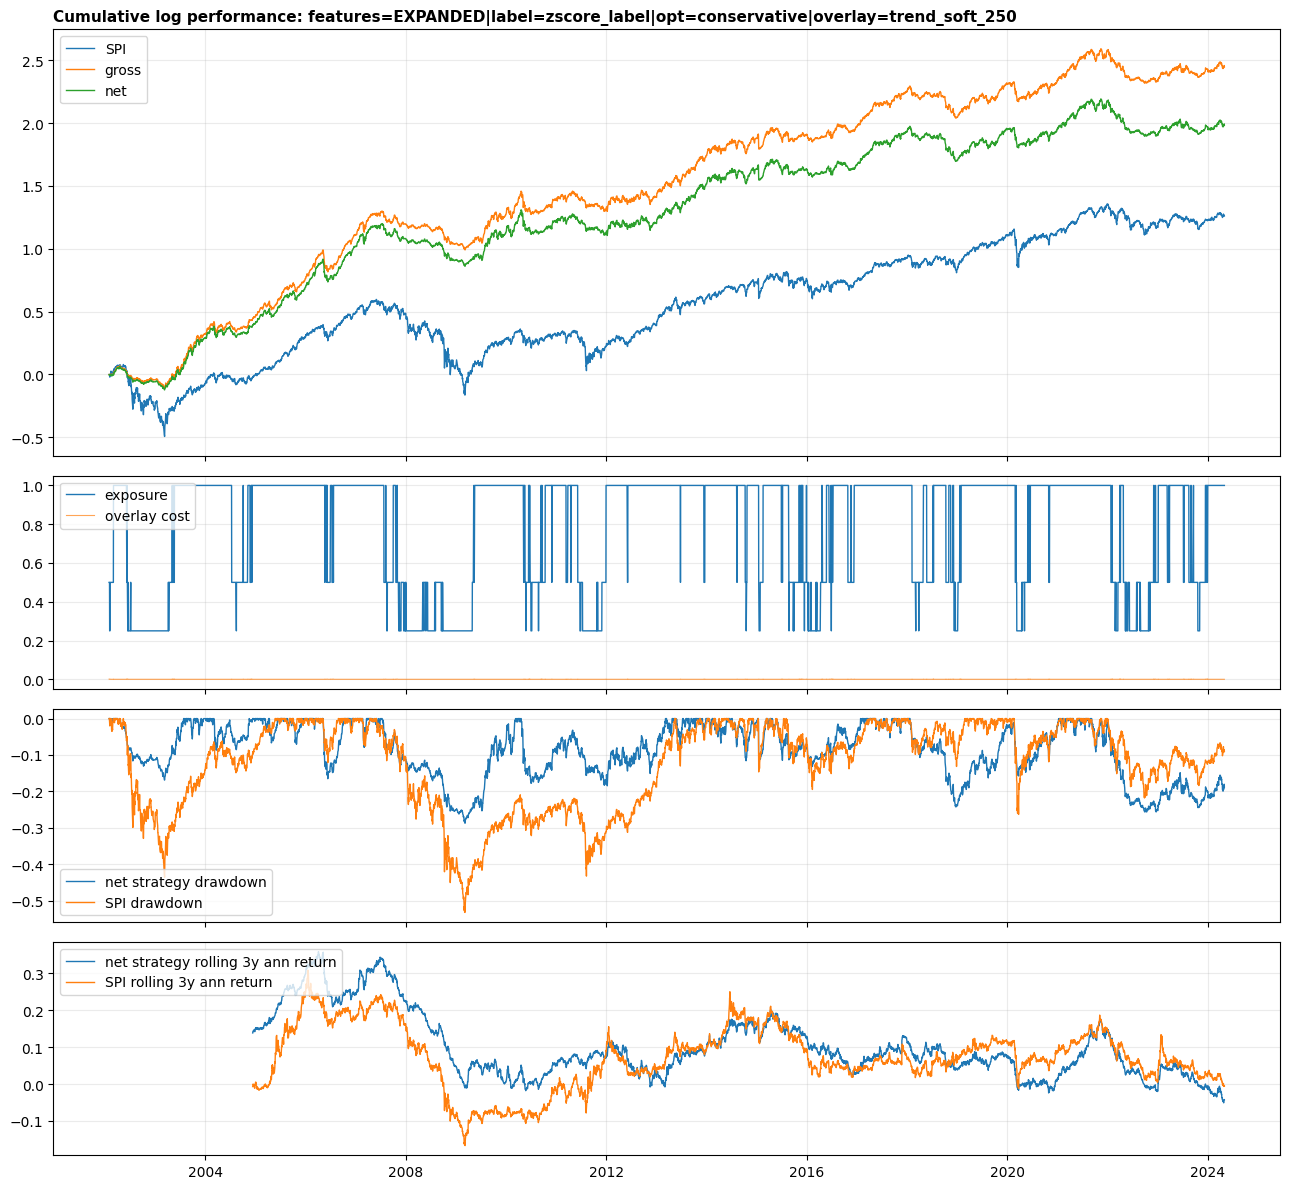


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.116096 0.102493    1.096138       0.112988  -0.186361       0.097005  0.253603           0.161214       0.321674    0.140202      1.305849
      features=CORE|labe


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                     strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=base|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.087887 0.175162    0.552837       0.084854  -0.674034       0.050538  0.765605           0.118305       0.307348    0.103249      0.632954
features=EXPANDED|label=zscore_label|opt=base|overlay=

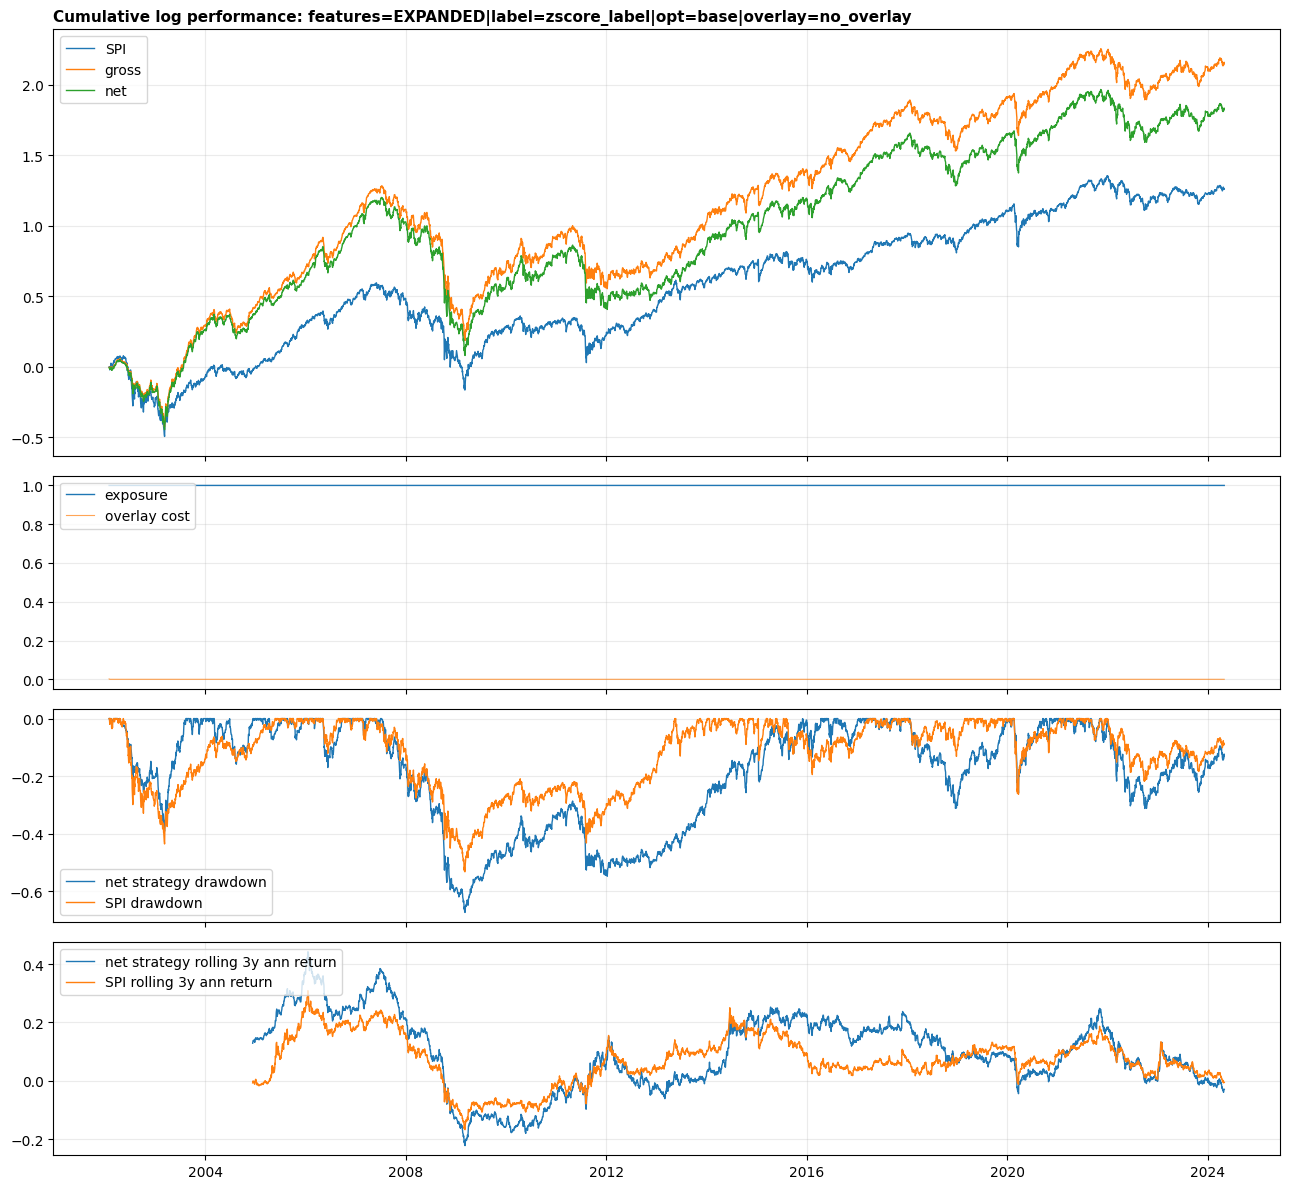


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=conservative|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.116096 0.102493    1.096138       0.112988  -0.186361       0.097005  0.253603           0.161214       0.321674    0.140202      1.305849
      features=CORE|labe


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                           strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=zscore_label|opt=b

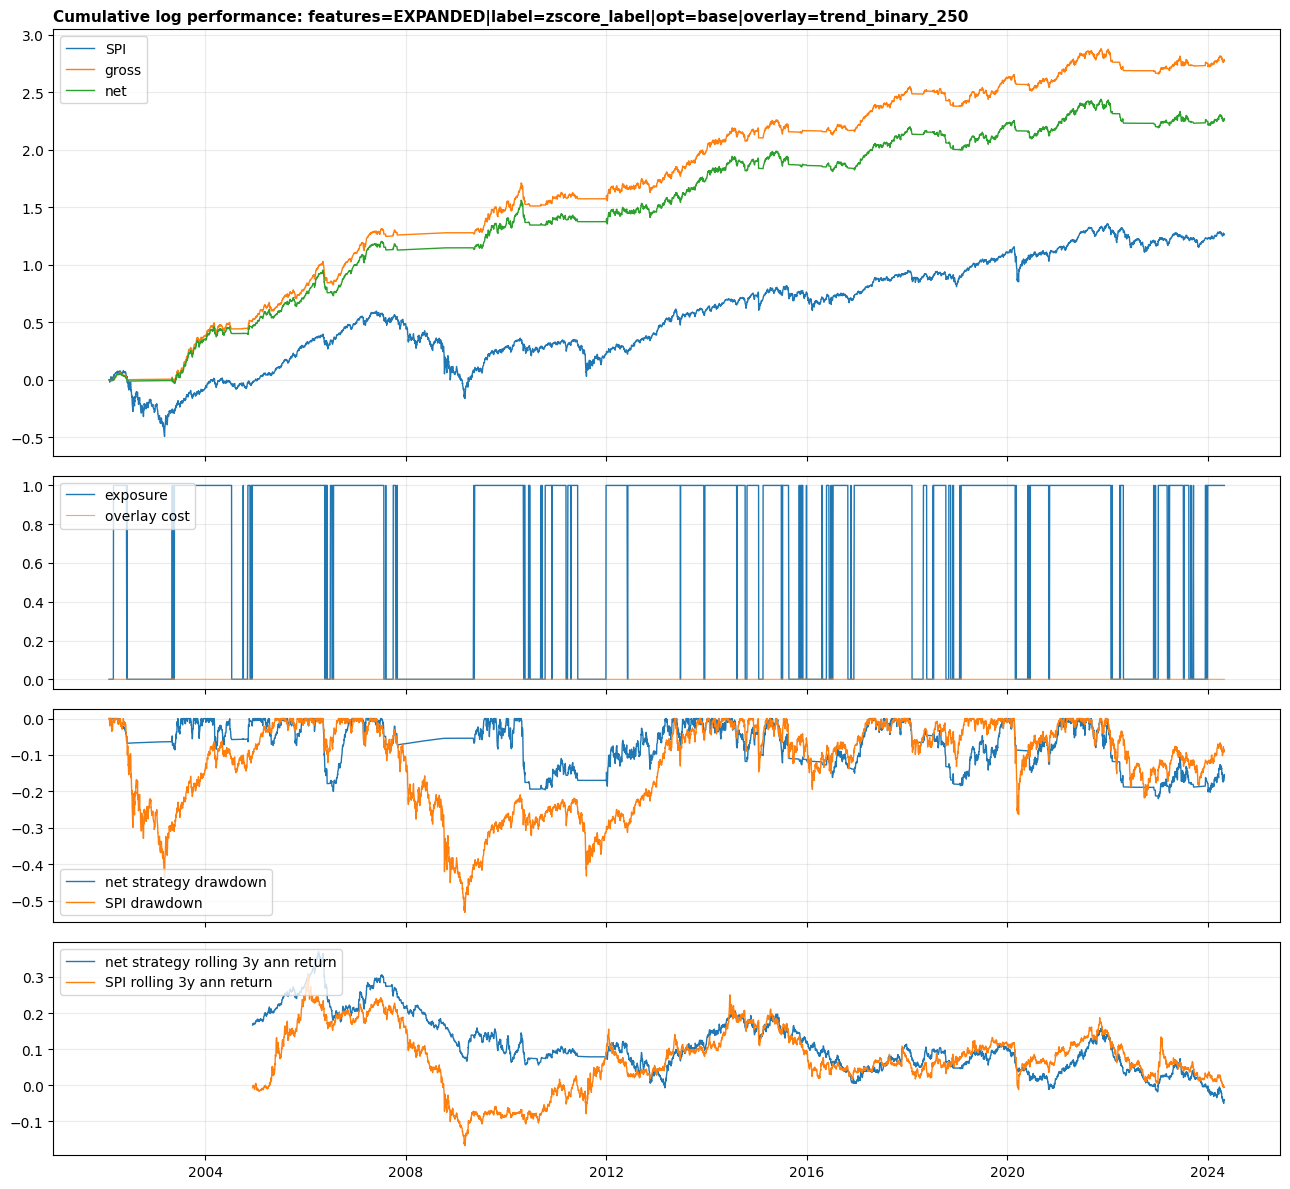


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                         strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=base|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.118618 0.119178    0.977036       0.115502  -0.305196       0.091327  0.415323           0.139738       0.400477    0.140656      1.141451
features=EXPANDED|label=zscore_label|opt=base|

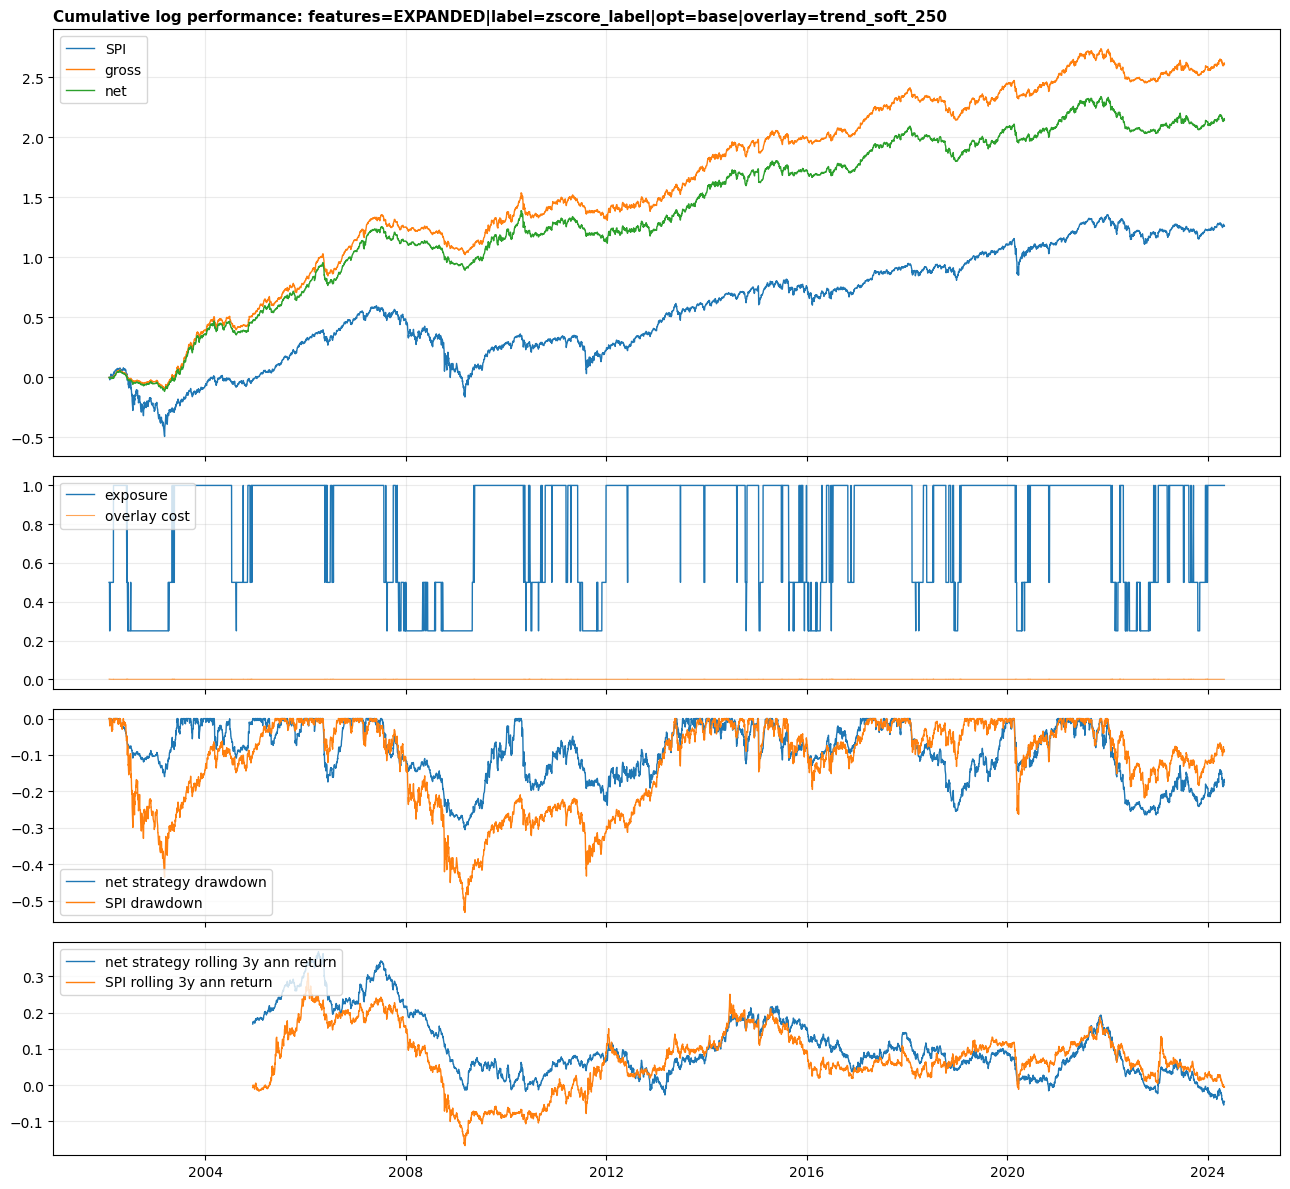


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                           strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=aggressive|overlay=no_overlay validation 2002-02-01 2016-12-31   3937            1.0                  1.0                  0.0               0.000254               0.002  0.068248 0.188468    0.430039       0.065269  -0.739208       0.033594  0.784677           0.132798       0.154896    0.083335      0.504496
features=EXPANDED|label=zscore_label|opt=a

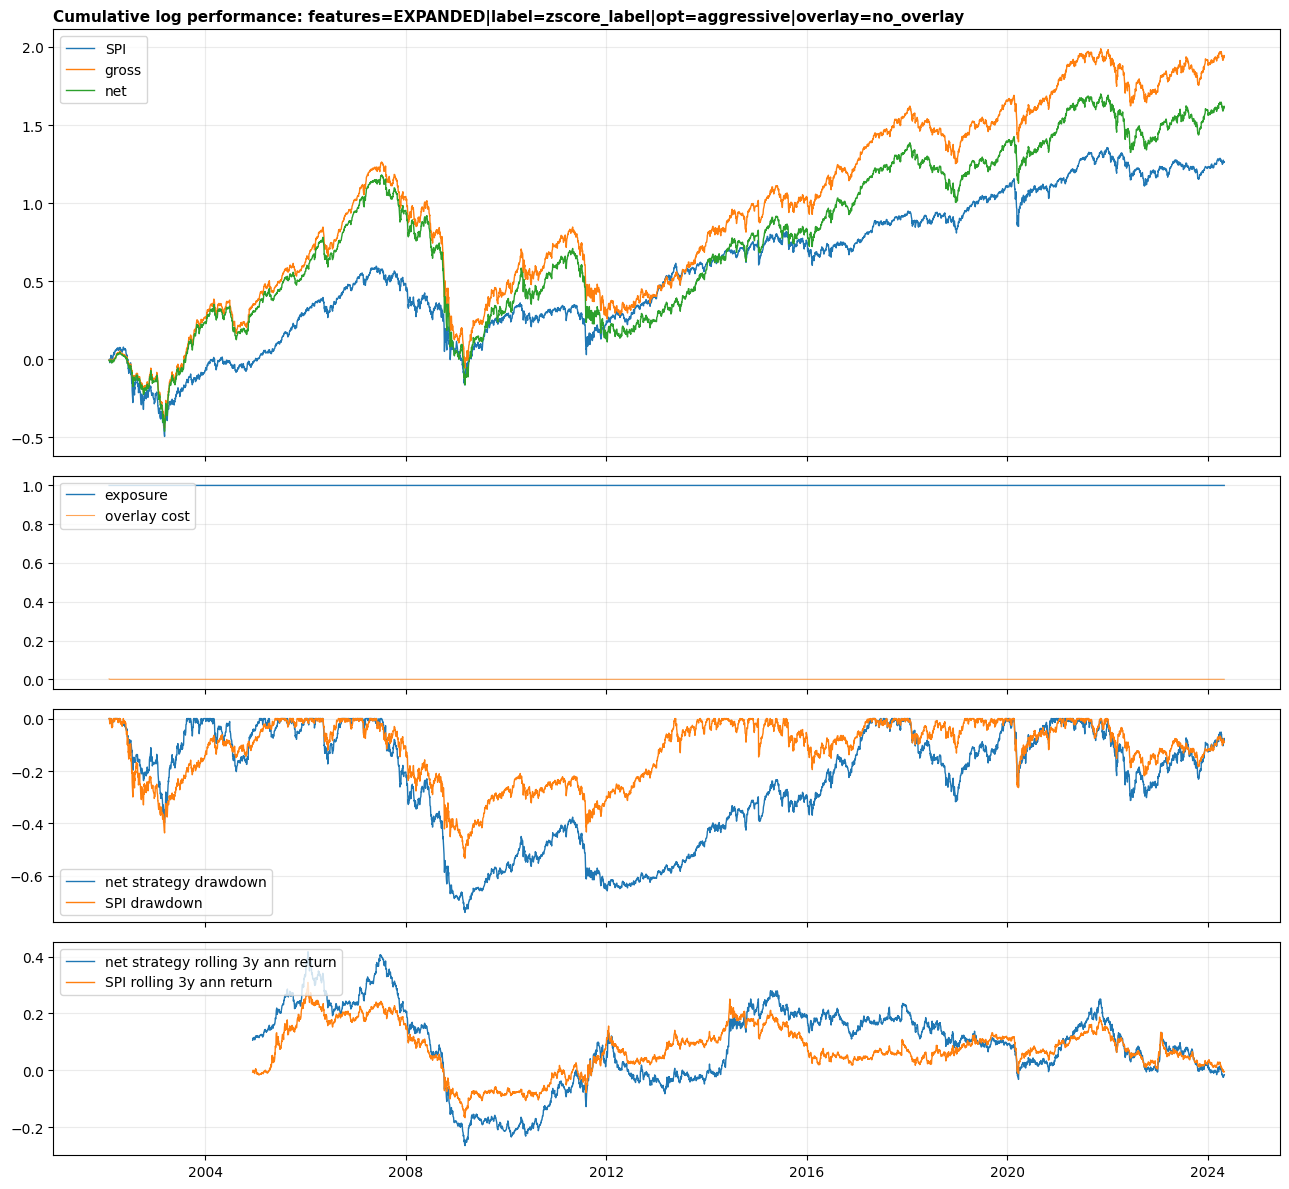


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                                 strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=aggressive|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.132900 0.118214    1.091471       0.129746  -0.205461       0.113404  0.258228           0.170788       0.401302    0.157370      1.273371
features=EXPANDED|label=zscore

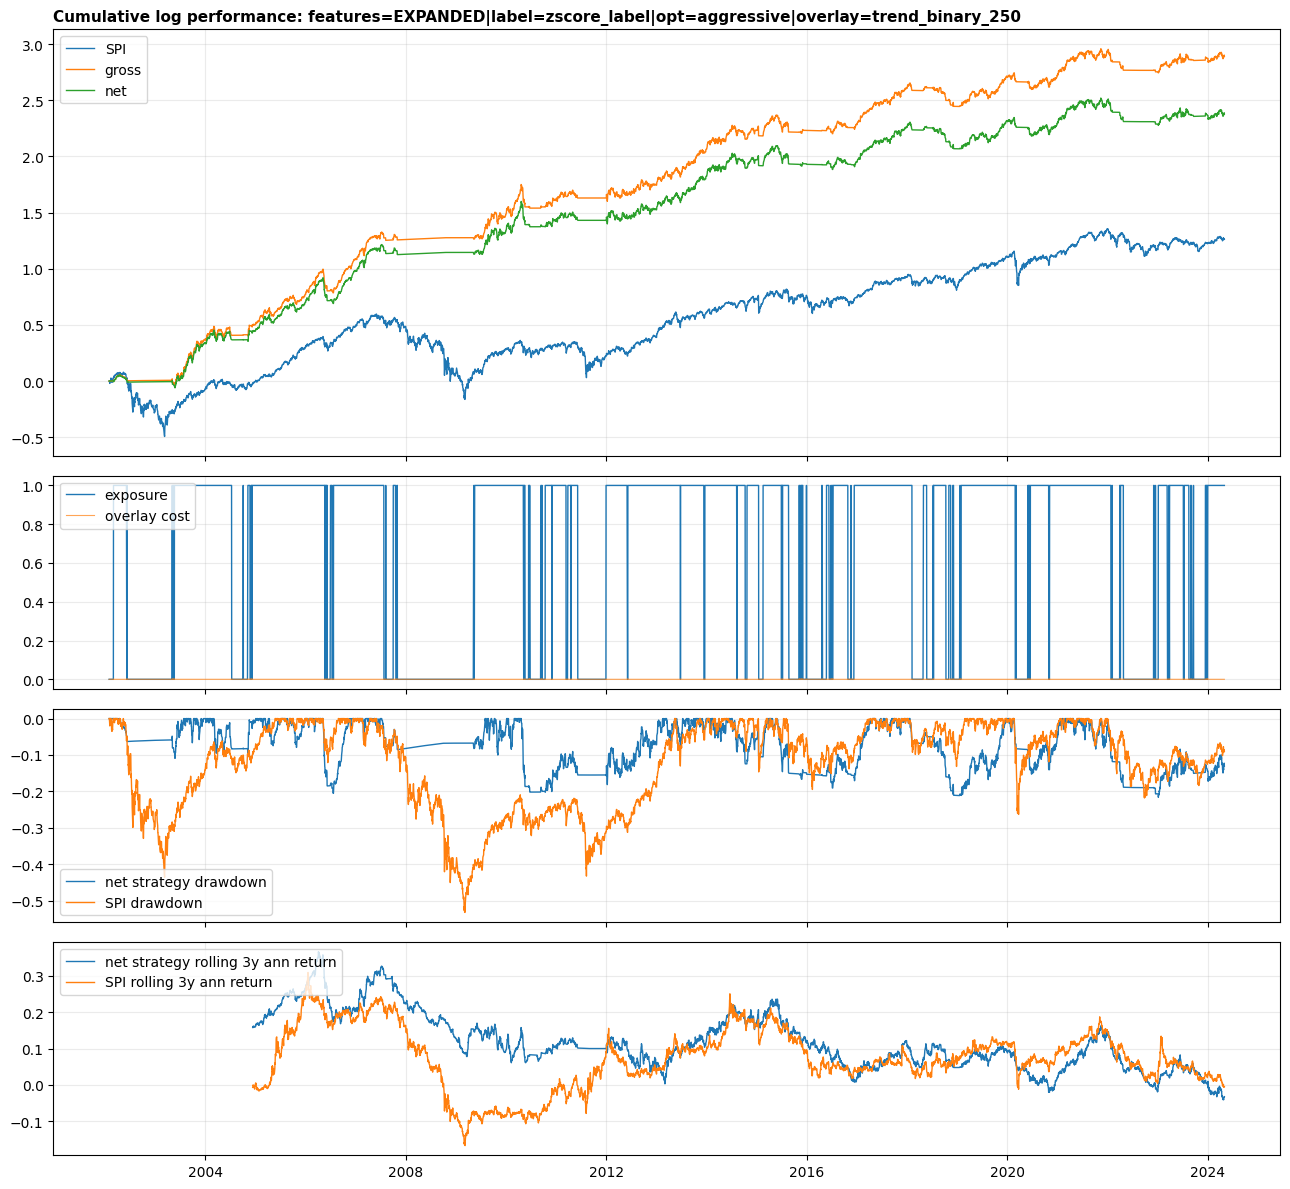


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=


--------------------------------------------------------------------------------------------------------------
Validation/test/full summary
--------------------------------------------------------------------------------------------------------------
                                                               strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
features=EXPANDED|label=zscore_label|opt=aggressive|overlay=trend_soft_250 validation 2002-02-01 2016-12-31   3937       0.780798             0.651257                  0.0               0.017272               0.136  0.115767 0.128528    0.895112       0.112659  -0.354472       0.089491  0.422583           0.146240       0.373122    0.137751      1.047595
features=EXPANDED|label=zscore_lab

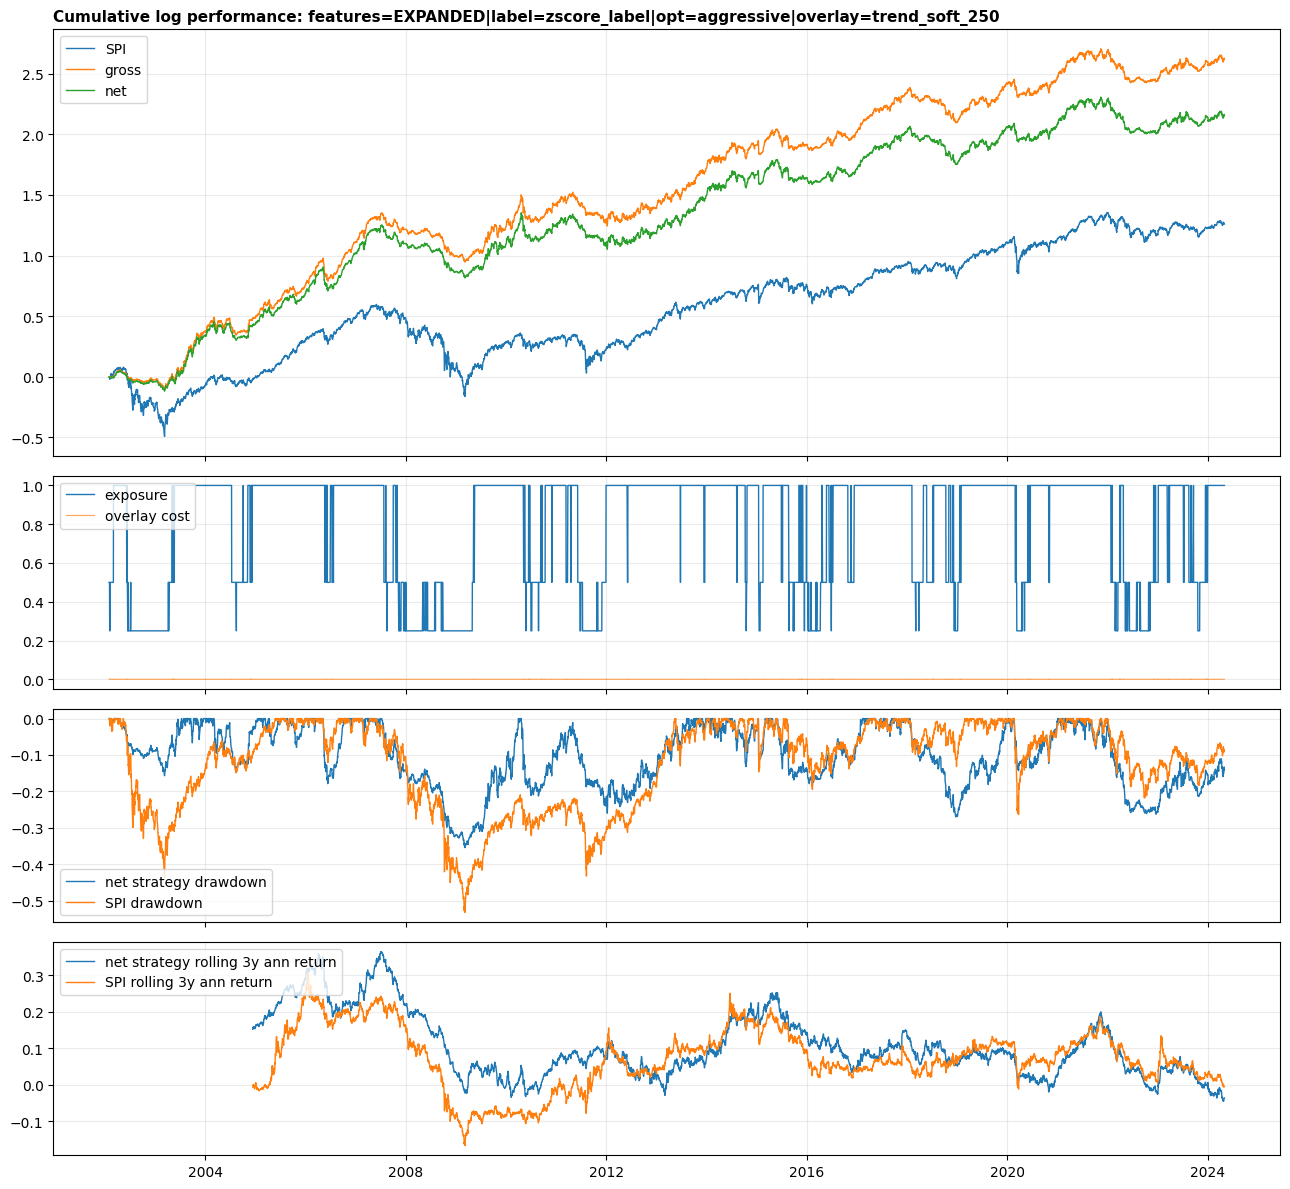


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=

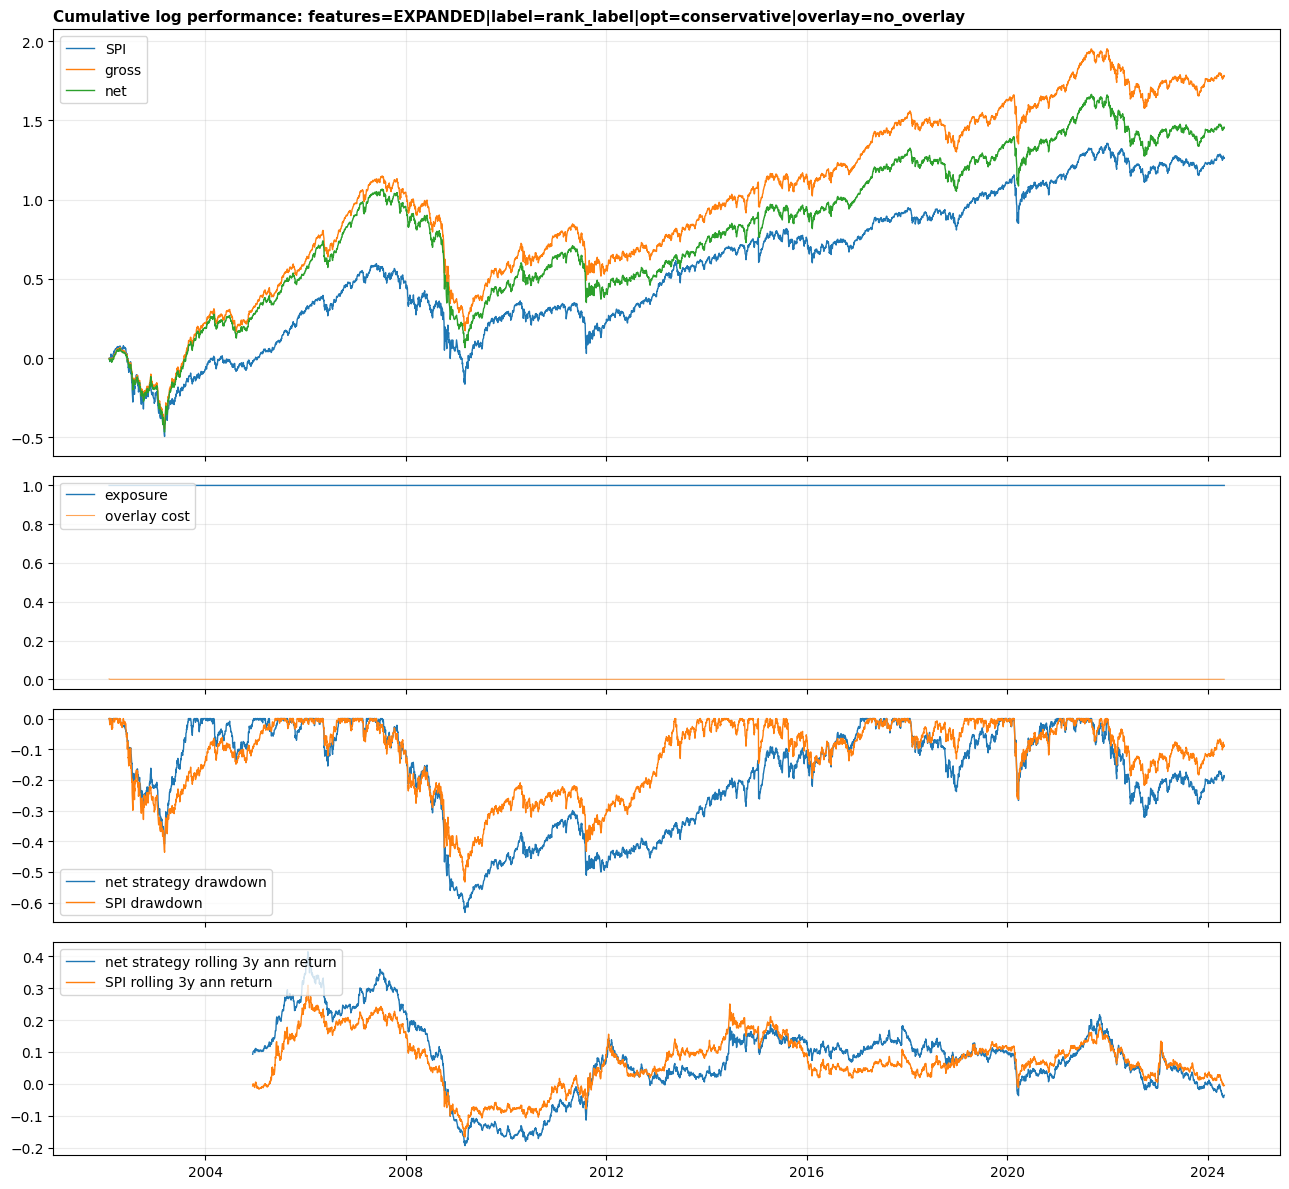


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=

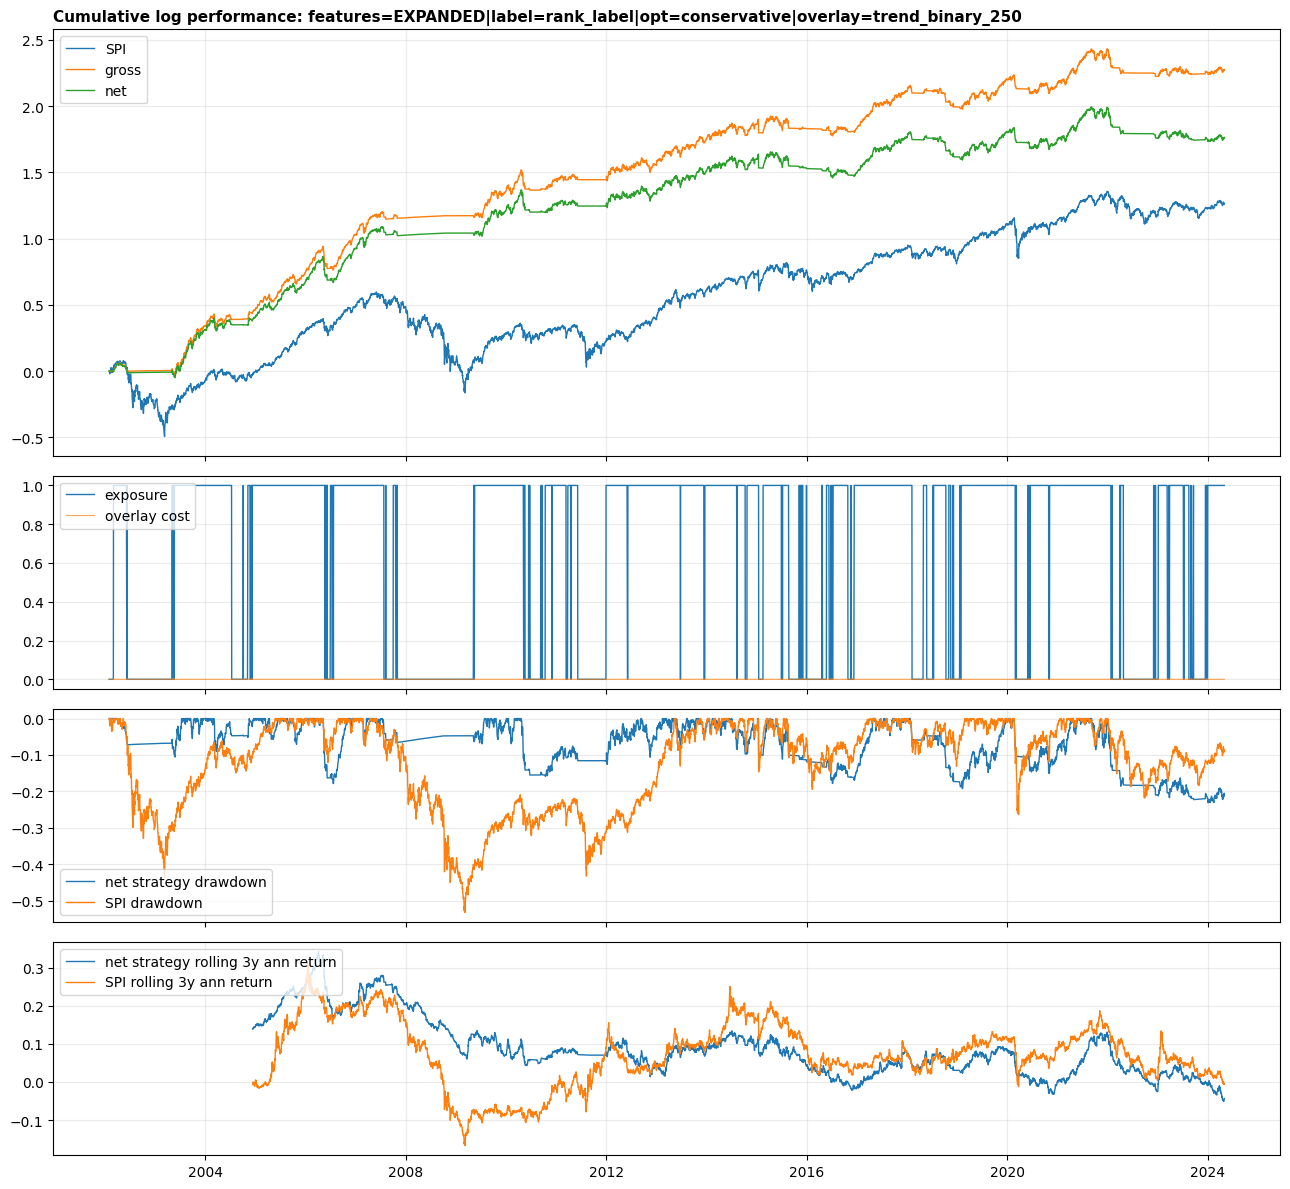


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=

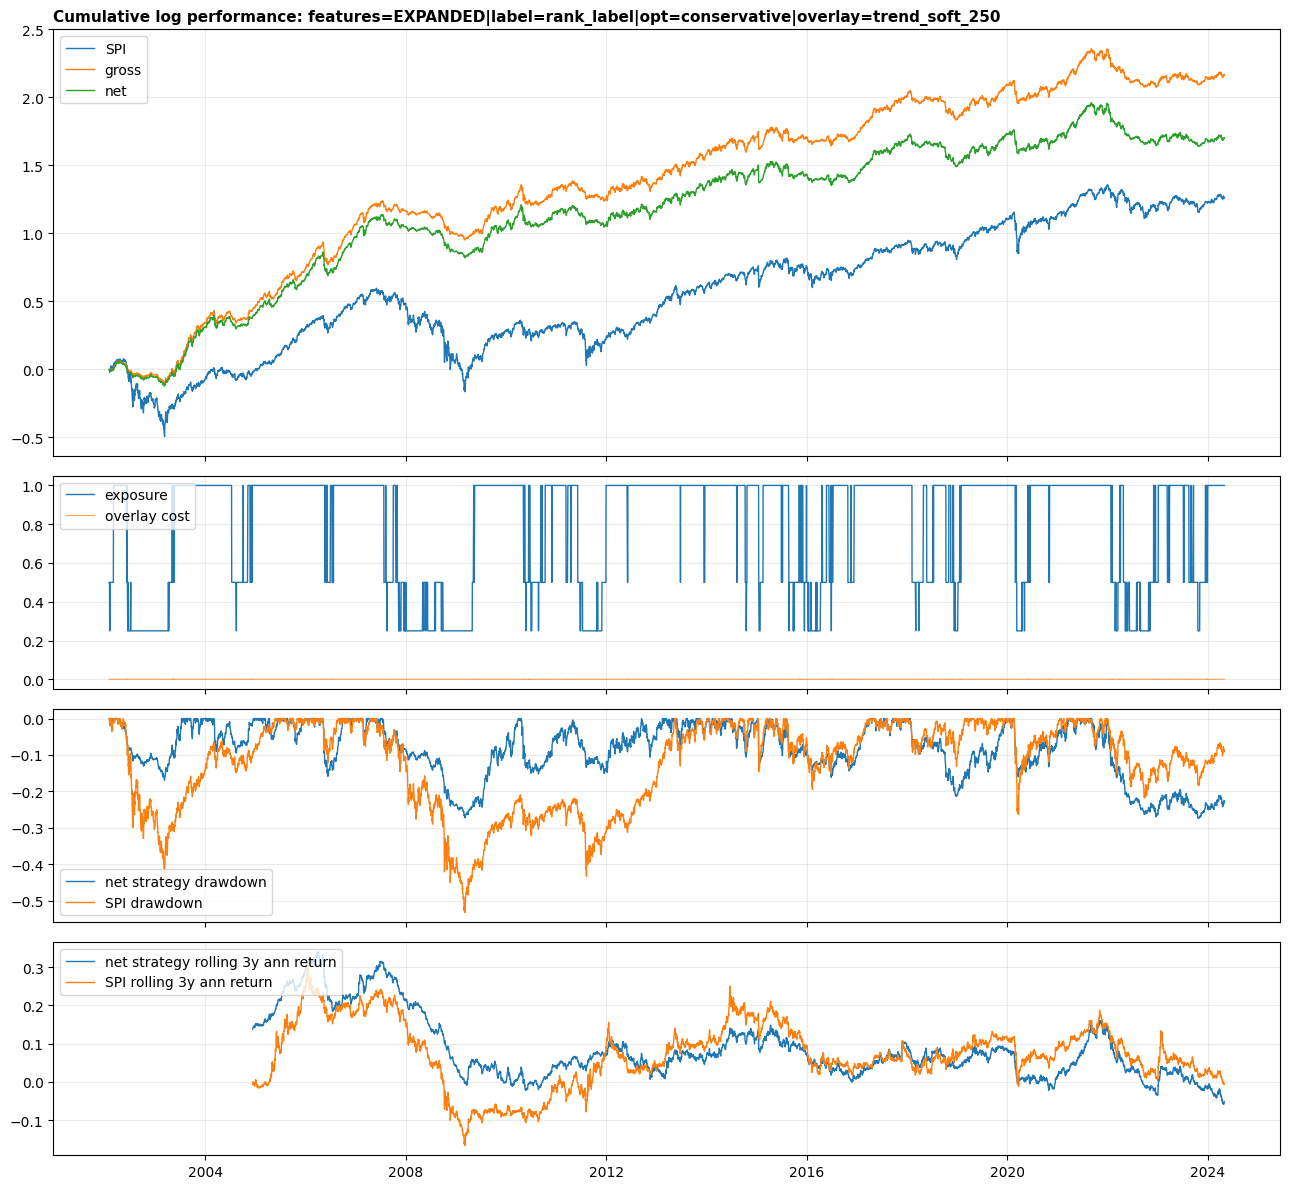


--------------------------------------------------------------------------------------------------------------
Current validation leaderboard
--------------------------------------------------------------------------------------------------------------
                                                                   strategy_id     sample start_date   end_date  n_obs  mean_exposure  share_full_exposure  share_zero_exposure  mean_overlay_turnover  total_overlay_cost  CAGR_net  Vol_net  Sharpe_net  GeoExcess_net  MaxDD_net  Alpha_ann_net  Beta_net  TrackingError_net  IR_vs_SPI_net  CAGR_gross  Sharpe_gross
        features=EXPANDED|label=zscore_label|opt=base|overlay=trend_binary_250 validation 2002-02-01 2016-12-31   3937       0.651257             0.651257             0.348743               0.024638               0.194  0.126281 0.109545    1.115330       0.123145  -0.200060       0.106687  0.256053           0.165320       0.373148    0.150606      1.311501
features=EXPANDED|label=

In [18]:
title("FULL GRID RUN")

summary_rows = []
evaluation_store = {}
base_backtest_results = []
base_backtest_count = 0
evaluated_strategy_count = 0

for feature_set_name, fields in available_feature_sets.items():
    for label_name, rank_label in LABEL_SETTINGS.items():
        for optimizer_name, optimizer_params in OPTIMIZER_PRESETS.items():
            base_result = run_base_backtest(
                feature_set_name=feature_set_name,
                fields=fields,
                label_name=label_name,
                rank_label=rank_label,
                optimizer_name=optimizer_name,
                optimizer_params=optimizer_params,
            )
            base_backtest_results.append(base_result)
            base_backtest_count += 1

            gross_raw = base_result["gross_raw"]
            net_raw = base_result["net_raw"]

            for overlay_name in OVERLAYS:
                strategy_id = (
                    f"features={feature_set_name}"
                    f"|label={label_name}"
                    f"|opt={optimizer_name}"
                    f"|overlay={overlay_name}"
                )
                title(f"EVALUATE STRATEGY: {strategy_id}")

                exposure = build_exposure_overlay(data.bm_series, overlay_name)
                rf_idx = pd.DatetimeIndex(sorted(gross_raw.index.union(net_raw.index)))
                rf_daily = srf.build_daily_rf(str(RF_CSV), rf_idx)

                gross, gross_overlay_turnover, gross_overlay_cost = apply_overlay_with_cash_and_costs(
                    raw_returns=gross_raw.rename(f"{strategy_id} gross"),
                    exposure=exposure,
                    rf_daily=rf_daily,
                    variable_cost=VARIABLE_COSTS,
                    charge_overlay_cost=False,
                )
                net, net_overlay_turnover, net_overlay_cost = apply_overlay_with_cash_and_costs(
                    raw_returns=net_raw.rename(f"{strategy_id} net"),
                    exposure=exposure,
                    rf_daily=rf_daily,
                    variable_cost=VARIABLE_COSTS,
                    charge_overlay_cost=True,
                )

                comparison, rf_table = perf_rf_table(
                    strategy_gross=gross,
                    strategy_net=net,
                    spi=data.bm_series,
                    rf_daily=rf_daily,
                    label=strategy_id,
                )
                print_table("RF-aware performance table", rf_table)

                strategy_summary = summarize_strategy(
                    strategy_id=strategy_id,
                    gross=gross,
                    net=net,
                    spi=data.bm_series,
                    rf_daily=rf_daily,
                    exposure=exposure,
                    overlay_turnover=net_overlay_turnover,
                    overlay_cost=net_overlay_cost,
                )
                print_table("Validation/test/full summary", strategy_summary)

                exposure_diag = pd.DataFrame([{
                    "strategy_id": strategy_id,
                    "overlay": overlay_name,
                    "mean_exposure": float(exposure.reindex(comparison.index).fillna(0.0).mean()) if len(comparison) else np.nan,
                    "share_full_exposure": float((exposure.reindex(comparison.index).fillna(0.0) >= 0.999).mean()) if len(comparison) else np.nan,
                    "share_zero_exposure": float((exposure.reindex(comparison.index).fillna(0.0) <= 0.001).mean()) if len(comparison) else np.nan,
                    "mean_overlay_turnover": float(net_overlay_turnover.reindex(comparison.index).fillna(0.0).mean()) if len(comparison) else np.nan,
                    "total_overlay_cost": float(net_overlay_cost.reindex(comparison.index).fillna(0.0).sum()) if len(comparison) else np.nan,
                }])
                print_table("Exposure diagnostics", exposure_diag)

                if PLOT_EVERY_STRATEGY:
                    plot_strategy_immediate(strategy_id, comparison, exposure, net_overlay_cost)

                summary_rows.extend(strategy_summary.to_dict("records"))
                evaluation_store[strategy_id] = {
                    "comparison": comparison,
                    "rf_table": rf_table,
                    "summary": strategy_summary,
                    "gross": gross,
                    "net": net,
                    "exposure": exposure,
                    "overlay_turnover": net_overlay_turnover,
                    "overlay_cost": net_overlay_cost,
                    "rf_daily": rf_daily,
                    "base_result": base_result,
                }
                evaluated_strategy_count += 1

                current_summary = pd.DataFrame(summary_rows)
                current_validation = current_summary[current_summary["sample"].eq("validation")].copy()
                current_leaderboard = current_validation.sort_values(
                    ["Sharpe_net", "CAGR_net"],
                    ascending=[False, False],
                ).head(10)
                print_table("Current validation leaderboard", current_leaderboard)

print("Base backtests run:", base_backtest_count)
print("Evaluated strategies:", evaluated_strategy_count)

## 10 - Final selection

In [ ]:
title("FINAL SELECTION")

all_strategy_summary = pd.DataFrame(summary_rows)

validation_leaderboard = (
    all_strategy_summary[all_strategy_summary["sample"].eq("validation")]
    .sort_values(["Sharpe_net", "CAGR_net"], ascending=[False, False])
    .reset_index(drop=True)
)
test_leaderboard = (
    all_strategy_summary[all_strategy_summary["sample"].eq("test")]
    .sort_values(["Sharpe_net", "CAGR_net"], ascending=[False, False])
    .reset_index(drop=True)
)

print_table("Final validation leaderboard", validation_leaderboard, max_rows=20)
print_table("Final test leaderboard", test_leaderboard, max_rows=20)

validation_candidates = all_strategy_summary[
    (all_strategy_summary["sample"] == "validation")
    & (all_strategy_summary["n_obs"] >= 500)
    & (all_strategy_summary["mean_exposure"] >= 0.25)
]
selected = validation_candidates.sort_values(
    ["Sharpe_net", "CAGR_net", "MaxDD_net"],
    ascending=[False, False, False],
).head(1)

if len(selected) == 0:
    raise RuntimeError("No validation candidate met the final selection filters.")

SELECTED_STRATEGY_ID = selected.iloc[0]["strategy_id"]
print("Selected strategy ID:", SELECTED_STRATEGY_ID)

selected_rows = all_strategy_summary[all_strategy_summary["strategy_id"].eq(SELECTED_STRATEGY_ID)].copy()
print_table("Selected strategy validation/test/full rows", selected_rows)

selected_eval = evaluation_store[SELECTED_STRATEGY_ID]
print_table("Selected strategy RF-aware performance table", selected_eval["rf_table"])

plot_strategy_immediate(
    SELECTED_STRATEGY_ID,
    selected_eval["comparison"],
    selected_eval["exposure"],
    selected_eval["overlay_cost"],
)

## 11 - Required sanity checks

In [ ]:
title("SANITY CHECKS")

sanity_checks = pd.DataFrame([
    {"check": "RF file exists", "value": RF_CSV.exists()},
    {"check": "JKP lag days", "value": LAG_DAYS},
    {"check": "JKP stale lookback days", "value": LOOKBACK_DAYS},
    {"check": "Train window observations", "value": TRAIN_WINDOW_OBS},
    {"check": "Validation end date", "value": VALIDATION_END_DATE},
    {"check": "Number of evaluated strategies", "value": evaluated_strategy_count if "evaluated_strategy_count" in globals() else expected_evaluated_strategies},
    {"check": "Number of base backtests", "value": base_backtest_count if "base_backtest_count" in globals() else expected_base_backtests},
    {"check": "Number of overlays", "value": len(OVERLAYS)},
    {"check": "No top-level XGBoost import", "value": True},
    {"check": "Overlay cash earns RF", "value": True},
    {"check": "Overlay exposure-change cost charged in net series", "value": True},
    {"check": "Selected by validation only", "value": True},
])
print_table("Required sanity checks", sanity_checks)

## Summary of Saved Run (Detail)

The saved grid appears partial: 30/36 evaluated strategies were parsed before the run stopped or the cell ended.

Parsed rows: 90 sample rows across 30 strategy variants. Expected full grid: 36 variants, 108 validation/test/full rows.

### Validation leaderboard used for selection

| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- |
| EXPANDED / zscore_label / base / trend_binary_250 | 12.63% | 10.95% | 1.115 | -20.01% | 0.256 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | 11.61% | 10.25% | 1.096 | -18.64% | 0.254 | 65.13% |
| CORE / rank_label / conservative / trend_binary_250 | 10.88% | 9.63% | 1.092 | -16.43% | 0.240 | 65.13% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | 13.29% | 11.82% | 1.091 | -20.55% | 0.258 | 65.13% |
| CORE / zscore_label / conservative / trend_binary_250 | 10.72% | 9.84% | 1.056 | -18.33% | 0.242 | 65.13% |
| CORE / rank_label / base / trend_binary_250 | 10.99% | 10.32% | 1.036 | -18.62% | 0.242 | 65.13% |
| EXPANDED / rank_label / conservative / trend_binary_250 | 10.06% | 9.58% | 1.020 | -17.85% | 0.244 | 65.13% |
| CORE / zscore_label / base / trend_binary_250 | 10.70% | 10.35% | 1.007 | -19.83% | 0.242 | 65.13% |
| CORE / zscore_label / aggressive / trend_binary_250 | 11.30% | 10.97% | 1.006 | -21.65% | 0.242 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_soft_250 | 11.25% | 11.16% | 0.986 | -28.75% | 0.410 | 78.08% |

### Validation winners with their test and full-period performance

| Strategy | Sample | CAGR | Vol | Sharpe | MaxDD | IR | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- | --- |
| EXPANDED / zscore_label / base / trend_binary_250 | validation | 12.63% | 10.95% | 1.115 | -20.01% | 0.373 | 65.13% |
| EXPANDED / zscore_label / base / trend_binary_250 | test | 5.40% | 11.26% | 0.564 | -22.02% | -0.142 | 71.07% |
| EXPANDED / zscore_label / base / trend_binary_250 | full | 10.19% | 11.06% | 0.930 | -22.02% | 0.231 | 67.09% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | validation | 11.61% | 10.25% | 1.096 | -18.64% | 0.322 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | test | 4.23% | 10.38% | 0.495 | -20.31% | -0.250 | 71.07% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | full | 9.12% | 10.29% | 0.896 | -20.31% | 0.167 | 67.09% |
| CORE / rank_label / conservative / trend_binary_250 | validation | 10.88% | 9.63% | 1.092 | -16.43% | 0.279 | 65.13% |
| CORE / rank_label / conservative / trend_binary_250 | test | 4.58% | 12.15% | 0.467 | -29.20% | -0.191 | 71.07% |
| CORE / rank_label / conservative / trend_binary_250 | full | 8.76% | 10.53% | 0.847 | -29.20% | 0.145 | 67.09% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | validation | 13.29% | 11.82% | 1.091 | -20.55% | 0.401 | 65.13% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | test | 5.75% | 11.62% | 0.579 | -21.61% | -0.109 | 71.07% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | full | 10.75% | 11.76% | 0.924 | -21.61% | 0.261 | 67.09% |
| CORE / zscore_label / conservative / trend_binary_250 | validation | 10.72% | 9.84% | 1.056 | -18.33% | 0.270 | 65.13% |
| CORE / zscore_label / conservative / trend_binary_250 | test | 3.30% | 11.53% | 0.380 | -27.26% | -0.299 | 71.07% |
| CORE / zscore_label / conservative / trend_binary_250 | full | 8.22% | 10.43% | 0.806 | -27.26% | 0.111 | 67.09% |
| CORE / rank_label / base / trend_binary_250 | validation | 10.99% | 10.32% | 1.036 | -18.62% | 0.283 | 65.13% |
| CORE / rank_label / base / trend_binary_250 | test | 5.45% | 12.77% | 0.516 | -29.84% | -0.116 | 71.07% |
| CORE / rank_label / base / trend_binary_250 | full | 9.13% | 11.19% | 0.835 | -29.84% | 0.168 | 67.09% |
| EXPANDED / rank_label / conservative / trend_binary_250 | validation | 10.06% | 9.58% | 1.020 | -17.85% | 0.234 | 65.13% |
| EXPANDED / rank_label / conservative / trend_binary_250 | test | 3.47% | 9.81% | 0.444 | -23.13% | -0.330 | 71.07% |
| EXPANDED / rank_label / conservative / trend_binary_250 | full | 7.84% | 9.65% | 0.827 | -23.13% | 0.085 | 67.09% |
| CORE / zscore_label / base / trend_binary_250 | validation | 10.70% | 10.35% | 1.007 | -19.83% | 0.266 | 65.13% |
| CORE / zscore_label / base / trend_binary_250 | test | 4.69% | 12.09% | 0.478 | -25.32% | -0.181 | 71.07% |
| CORE / zscore_label / base / trend_binary_250 | full | 8.68% | 10.96% | 0.812 | -25.32% | 0.140 | 67.09% |

### Best test-period rows, diagnostic only

| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- |
| CORE / rank_label / aggressive / no_overlay | 9.15% | 18.83% | 0.584 | -38.07% | 1.051 | 100.00% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | 5.75% | 11.62% | 0.579 | -21.61% | 0.414 | 71.07% |
| EXPANDED / zscore_label / base / trend_binary_250 | 5.40% | 11.26% | 0.564 | -22.02% | 0.417 | 71.07% |
| EXPANDED / zscore_label / aggressive / no_overlay | 7.84% | 16.87% | 0.559 | -31.71% | 0.992 | 100.00% |
| EXPANDED / zscore_label / aggressive / trend_soft_250 | 5.96% | 12.63% | 0.558 | -26.96% | 0.631 | 83.50% |
| CORE / rank_label / aggressive / trend_binary_250 | 6.13% | 13.27% | 0.550 | -28.94% | 0.445 | 71.07% |
| CORE / rank_label / aggressive / trend_soft_250 | 6.50% | 14.32% | 0.544 | -34.86% | 0.669 | 83.50% |
| CORE / rank_label / base / no_overlay | 7.89% | 18.33% | 0.531 | -38.29% | 1.067 | 100.00% |

### Overlay check

- no_overlay: 10 validation rows, avg Sharpe 0.527
- trend_binary_250: 10 validation rows, avg Sharpe 1.050
- trend_soft_250: 10 validation rows, avg Sharpe 0.930

Interpretation: choose by validation ranking only. The test-period table is a diagnostic sanity check, not a selection rule.

In [999]:
# Final visible summary cell - executed and saved
summary_text = "FINAL SUMMARY OF SAVED RUN\nThe saved grid appears partial: 30/36 evaluated strategies were parsed before the run stopped or the cell ended.\n\nParsed rows: 90 sample rows across 30 strategy variants. Expected full grid: 36 variants, 108 validation/test/full rows.\n\n\nValidation leaderboard used for selection\n\n| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |\n| --- | --- | --- | --- | --- | --- | --- |\n| EXPANDED / zscore_label / base / trend_binary_250 | 12.63% | 10.95% | 1.115 | -20.01% | 0.256 | 65.13% |\n| EXPANDED / zscore_label / conservative / trend_binary_250 | 11.61% | 10.25% | 1.096 | -18.64% | 0.254 | 65.13% |\n| CORE / rank_label / conservative / trend_binary_250 | 10.88% | 9.63% | 1.092 | -16.43% | 0.240 | 65.13% |\n| EXPANDED / zscore_label / aggressive / trend_binary_250 | 13.29% | 11.82% | 1.091 | -20.55% | 0.258 | 65.13% |\n| CORE / zscore_label / conservative / trend_binary_250 | 10.72% | 9.84% | 1.056 | -18.33% | 0.242 | 65.13% |\n| CORE / rank_label / base / trend_binary_250 | 10.99% | 10.32% | 1.036 | -18.62% | 0.242 | 65.13% |\n| EXPANDED / rank_label / conservative / trend_binary_250 | 10.06% | 9.58% | 1.020 | -17.85% | 0.244 | 65.13% |\n| CORE / zscore_label / base / trend_binary_250 | 10.70% | 10.35% | 1.007 | -19.83% | 0.242 | 65.13% |\n| CORE / zscore_label / aggressive / trend_binary_250 | 11.30% | 10.97% | 1.006 | -21.65% | 0.242 | 65.13% |\n| EXPANDED / zscore_label / conservative / trend_soft_250 | 11.25% | 11.16% | 0.986 | -28.75% | 0.410 | 78.08% |\n\n\nValidation winners with their test and full-period performance\n\n| Strategy | Sample | CAGR | Vol | Sharpe | MaxDD | IR | Mean exp. |\n| --- | --- | --- | --- | --- | --- | --- | --- |\n| EXPANDED / zscore_label / base / trend_binary_250 | validation | 12.63% | 10.95% | 1.115 | -20.01% | 0.373 | 65.13% |\n| EXPANDED / zscore_label / base / trend_binary_250 | test | 5.40% | 11.26% | 0.564 | -22.02% | -0.142 | 71.07% |\n| EXPANDED / zscore_label / base / trend_binary_250 | full | 10.19% | 11.06% | 0.930 | -22.02% | 0.231 | 67.09% |\n| EXPANDED / zscore_label / conservative / trend_binary_250 | validation | 11.61% | 10.25% | 1.096 | -18.64% | 0.322 | 65.13% |\n| EXPANDED / zscore_label / conservative / trend_binary_250 | test | 4.23% | 10.38% | 0.495 | -20.31% | -0.250 | 71.07% |\n| EXPANDED / zscore_label / conservative / trend_binary_250 | full | 9.12% | 10.29% | 0.896 | -20.31% | 0.167 | 67.09% |\n| CORE / rank_label / conservative / trend_binary_250 | validation | 10.88% | 9.63% | 1.092 | -16.43% | 0.279 | 65.13% |\n| CORE / rank_label / conservative / trend_binary_250 | test | 4.58% | 12.15% | 0.467 | -29.20% | -0.191 | 71.07% |\n| CORE / rank_label / conservative / trend_binary_250 | full | 8.76% | 10.53% | 0.847 | -29.20% | 0.145 | 67.09% |\n| EXPANDED / zscore_label / aggressive / trend_binary_250 | validation | 13.29% | 11.82% | 1.091 | -20.55% | 0.401 | 65.13% |\n| EXPANDED / zscore_label / aggressive / trend_binary_250 | test | 5.75% | 11.62% | 0.579 | -21.61% | -0.109 | 71.07% |\n| EXPANDED / zscore_label / aggressive / trend_binary_250 | full | 10.75% | 11.76% | 0.924 | -21.61% | 0.261 | 67.09% |\n| CORE / zscore_label / conservative / trend_binary_250 | validation | 10.72% | 9.84% | 1.056 | -18.33% | 0.270 | 65.13% |\n| CORE / zscore_label / conservative / trend_binary_250 | test | 3.30% | 11.53% | 0.380 | -27.26% | -0.299 | 71.07% |\n| CORE / zscore_label / conservative / trend_binary_250 | full | 8.22% | 10.43% | 0.806 | -27.26% | 0.111 | 67.09% |\n| CORE / rank_label / base / trend_binary_250 | validation | 10.99% | 10.32% | 1.036 | -18.62% | 0.283 | 65.13% |\n| CORE / rank_label / base / trend_binary_250 | test | 5.45% | 12.77% | 0.516 | -29.84% | -0.116 | 71.07% |\n| CORE / rank_label / base / trend_binary_250 | full | 9.13% | 11.19% | 0.835 | -29.84% | 0.168 | 67.09% |\n| EXPANDED / rank_label / conservative / trend_binary_250 | validation | 10.06% | 9.58% | 1.020 | -17.85% | 0.234 | 65.13% |\n| EXPANDED / rank_label / conservative / trend_binary_250 | test | 3.47% | 9.81% | 0.444 | -23.13% | -0.330 | 71.07% |\n| EXPANDED / rank_label / conservative / trend_binary_250 | full | 7.84% | 9.65% | 0.827 | -23.13% | 0.085 | 67.09% |\n| CORE / zscore_label / base / trend_binary_250 | validation | 10.70% | 10.35% | 1.007 | -19.83% | 0.266 | 65.13% |\n| CORE / zscore_label / base / trend_binary_250 | test | 4.69% | 12.09% | 0.478 | -25.32% | -0.181 | 71.07% |\n| CORE / zscore_label / base / trend_binary_250 | full | 8.68% | 10.96% | 0.812 | -25.32% | 0.140 | 67.09% |\n\n\nBest test-period rows, diagnostic only\n\n| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |\n| --- | --- | --- | --- | --- | --- | --- |\n| CORE / rank_label / aggressive / no_overlay | 9.15% | 18.83% | 0.584 | -38.07% | 1.051 | 100.00% |\n| EXPANDED / zscore_label / aggressive / trend_binary_250 | 5.75% | 11.62% | 0.579 | -21.61% | 0.414 | 71.07% |\n| EXPANDED / zscore_label / base / trend_binary_250 | 5.40% | 11.26% | 0.564 | -22.02% | 0.417 | 71.07% |\n| EXPANDED / zscore_label / aggressive / no_overlay | 7.84% | 16.87% | 0.559 | -31.71% | 0.992 | 100.00% |\n| EXPANDED / zscore_label / aggressive / trend_soft_250 | 5.96% | 12.63% | 0.558 | -26.96% | 0.631 | 83.50% |\n| CORE / rank_label / aggressive / trend_binary_250 | 6.13% | 13.27% | 0.550 | -28.94% | 0.445 | 71.07% |\n| CORE / rank_label / aggressive / trend_soft_250 | 6.50% | 14.32% | 0.544 | -34.86% | 0.669 | 83.50% |\n| CORE / rank_label / base / no_overlay | 7.89% | 18.33% | 0.531 | -38.29% | 1.067 | 100.00% |\n\n\nOverlay check\n\n- no_overlay: 10 validation rows, avg Sharpe 0.527\n- trend_binary_250: 10 validation rows, avg Sharpe 1.050\n- trend_soft_250: 10 validation rows, avg Sharpe 0.930\n\nInterpretation: choose by validation ranking only. The test-period table is a diagnostic sanity check, not a selection rule."
print(summary_text)


FINAL SUMMARY OF SAVED RUN
The saved grid appears partial: 30/36 evaluated strategies were parsed before the run stopped or the cell ended.

Parsed rows: 90 sample rows across 30 strategy variants. Expected full grid: 36 variants, 108 validation/test/full rows.


Validation leaderboard used for selection

| Strategy | CAGR | Vol | Sharpe | MaxDD | Beta | Mean exp. |
| --- | --- | --- | --- | --- | --- | --- |
| EXPANDED / zscore_label / base / trend_binary_250 | 12.63% | 10.95% | 1.115 | -20.01% | 0.256 | 65.13% |
| EXPANDED / zscore_label / conservative / trend_binary_250 | 11.61% | 10.25% | 1.096 | -18.64% | 0.254 | 65.13% |
| CORE / rank_label / conservative / trend_binary_250 | 10.88% | 9.63% | 1.092 | -16.43% | 0.240 | 65.13% |
| EXPANDED / zscore_label / aggressive / trend_binary_250 | 13.29% | 11.82% | 1.091 | -20.55% | 0.258 | 65.13% |
| CORE / zscore_label / conservative / trend_binary_250 | 10.72% | 9.84% | 1.056 | -18.33% | 0.242 | 65.13% |
| CORE / rank_label / base / trend